# M20 · Tenseurs, axes et estimateurs pondérés — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookMaths/blob/main/chapitres/m20_tenseurs_normalisation/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wbm.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | M20.1 à M20.5, M20.8 | Les exercices papier (vérification) | ✏️ 🔗 | | |
| A | M20.10 | `einsum` pour deux tableaux, avec des boucles · `einsum_pair` | 🔨 | ★★ | 45 |
|  | M20.11 | Moyennes et variances le long d'axes choisis · `moments_along_axes` | 🔨 | ★ | 25 |
|  | M20.12 | L'estimateur de Horvitz-Thompson d'un total · `horvitz_thompson_total` | 🔨 | ★ | 15 |
| B | M20.13 | Prédire la forme d'une réduction ou d'un einsum, puis vérifier | 🔮 | ★ | 10 |
|  | M20.14 | Simuler un sondage : Horvitz-Thompson contre la moyenne naïve, biais et variance | 🔬 | ★★ | 20 |
|  | M20.15 | Le produit de L jacobiennes I + hJ : ses valeurs singulières extrêmes quand L grandit, à hL fixé | 🎨 | ★ | 20 |
| C | M20.16 | Chasse à l'erreur : une moyenne sur le mauvais axe, une diffusion silencieuse, un ddof oublié | 🐛 | ★ | 15 |
|  | M20.17 | Un test de propriété : réduire sur deux axes d'un coup, ou l'un après l'autre | 🛠️ | ★ | 25 |
| D | M20.18 | Défi : des probabilités d'inclusion proportionnelles à la taille, et un estimateur presque sans variance | 🏆 | ★★★ | 25 |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (a few seconds per cell); False = bigger experiments
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookMaths.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookMaths")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WBM_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wbm").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wbm").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier de workbookMaths.")

os.environ["WBM_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wbm  # noqa: E402

cfg = wbm.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mymath = wbm.load_mymath("ref")  # reference implementation

🧪 workbookMaths : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.18 | numpy 2.1.3 | scipy 1.16.3 | sympy 1.14.0 | matplotlib 3.10.0 | pandas 2.2.3 | scikit-learn 1.6.1
   Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Vérifier tes calculs papier (partie 0) : des formes après réductions et remodelages, la notation d'Einstein et le coût d'une contraction, la matrice de centrage et la standardisation, un sondage de Horvitz-Thompson, un schéma d'Euler en $L$ pas, et un pont.
- Écrire les trois fonctions de `mymath/tensors.py` (`einsum_pair`, `moments_along_axes`, `horvitz_thompson_total`) et les tester.
- Prédire des formes puis les voir, comparer trois estimateurs d'un total par la simulation, dessiner le produit de $L$ pas d'Euler à horizon fixé, corriger trois erreurs classiques, écrire un test de propriété, et relever un défi : des probabilités proportionnelles à la taille.

**Rappel express.** Un tableau de forme $(n_0, \ldots, n_{k-1})$ ; en ordre C, $[i_0, i_1, i_2]$ est à la position $(i_0n_1 + i_1)\,n_2 + i_2$ ; `reshape` relit la file dans l'ordre C, `transpose` change l'ordre des axes. Réduire fait disparaître l'axe nommé ; `keepdims=True` le garde, de longueur 1. Diffusion : formes alignées à droite, longueurs égales ou 1 ; $(n,)$ contre $(n, 1)$ donne $(n, n)$. Variance : $\frac{1}{N - \text{ddof}}\sum (x - \bar x)^2$. `einsum` : une lettre absente du résultat est sommée ; coût, le produit des longueurs de toutes les lettres. $\mathbf{C} = \mathbf{I} - \frac1m\mathbf{1}\mathbf{1}^\top$, projection orthogonale de trace $m - 1$ ; la standardisation de $a\mathbf{x} + b\mathbf{1}$, $a > 0$, est celle de $\mathbf{x}$. Horvitz-Thompson : $\hat Y = \sum_{i \in S} y_i/\pi_i$, sans biais ; $\mathbb{V}(\hat Y) = \sum_i y_i^2\frac{1 - \pi_i}{\pi_i}$ en tirage de Poisson. Euler : $\mathbf{I} + h\mathbf{J}$ ; $L$ pas à horizon $T = hL$ fixé restent entre $(1 - hK)^L$ et $e^{KT}$, et $(\mathbf{I} + \frac TL\mathbf{J})^L \to e^{T\mathbf{J}}$.

## Partie 0 · Vérifier tes exercices papier (✏️ M20.1 à M20.5, 🔗 M20.8)

Fais d'abord les exercices de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse ici : **la valeur** que tu as trouvée, sous la forme indiquée en commentaire, jamais le calcul qui y mène :
- un entier, ou un nombre avec un point décimal, `-1.25`, arrondi comme le demande la question (une valeur exacte se tape aussi comme une fraction, `1/8`) ;
- une **forme** comme un tuple, `(7, 2)`, ou comme un texte, `"(7, 2)"` ; une forme à un seul axe s'écrit avec sa virgule, `(9,)` ;
- une liste `[0.2, -1]` ; une matrice comme la liste de ses **lignes**, `[[1, 0], [-2, 3]]`, un nombre décimal s'y écrivant avec un point ;
- une fraction irréductible entre guillemets, `"3/7"`, quand la question le dit ;
- une formule d'`einsum` entre guillemets, `"ab,b->a"`, avec les lettres que l'énoncé impose (les espaces et les majuscules ne comptent pas) ;
- une lettre entre guillemets pour un choix, `"D"` ; `True` ou `False` pour un vrai ou faux.

Les réponses pas encore remplies affichent ⏳.

In [2]:
# Part 0: the answers are computed from the statements (NumPy, exact fractions)
import math
from fractions import Fraction
from itertools import product

import numpy as np
import scipy.linalg


def shape_of(array):
    """The shape of an array, written as NumPy prints it: "(12, 28)", "(5,)"."""
    return str(tuple(int(n) for n in np.shape(array)))


def fractions_list(values):
    """Exact numbers as a list: Python ints for the integers, floats for the others."""
    return [int(v) if Fraction(v).denominator == 1 else float(v) for v in values]


SHAPE_1 = (12, 28, 24)                                                                     # M20.1
T_1 = np.zeros(SHAPE_1)                      # 12 stations × 28 days × 24 hours (the values do not matter)
R_1 = T_1.reshape(12, 4, 7, 24)              # 4 weeks of 7 days
try:
    T_1 - T_1.mean(axis=1)                   # (12, 28, 24) against (12, 24)
    H_1 = False
except ValueError:
    H_1 = True
A_2 = np.array([[1, 2], [0, -1], [3, 1]])                                                   # M20.2
B_2 = np.array([[2, 0, 1], [1, -1, 4]])
M_2, X_2, Y_2 = np.array([[2, -1], [0, 3]]), np.array([1, 2]), np.array([4, -1])
MS_2 = np.array([[[1, 2], [0, 1]], [[2, 0], [1, 3]], [[0, -1], [1, 0]]])
VS_2 = np.array([[1, 1], [2, -1], [3, 2]])
FORMULA_AB_2, FORMULA_TRACE_2 = "ij,jk->ik", "ij,ji->"
AB_2, BA_2 = A_2 @ B_2, B_2 @ A_2
assert np.array_equal(np.einsum(FORMULA_AB_2, A_2, B_2), AB_2)
assert np.einsum(FORMULA_TRACE_2, A_2, B_2) == np.trace(AB_2)
COST_H_2 = 10 * 4 * 6 * 5                    # the lengths of all the letters s, i, j, k
COST_I_2 = 30 * 300 * 5 + 30 * 5 * 50        # P (30, 300), Q (300, 5), R (5, 50): PQ, then (PQ)R
COST_J_2 = 300 * 5 * 50 + 30 * 300 * 50      # QR, then P(QR)
X_3 = [Fraction(v) for v in (3, 7, 4, 9, 5, 8)]                                            # M20.3
M_3 = len(X_3)
MEAN_3 = sum(X_3) / M_3
C_3 = [[Fraction(int(i == j)) - Fraction(1, M_3) for j in range(M_3)] for i in range(M_3)]
CX_3 = [sum(C_3[i][j] * X_3[j] for j in range(M_3)) for i in range(M_3)]
TRACE_3 = sum(C_3[i][i] for i in range(M_3))
NORM2_CX_3 = sum(v * v for v in CX_3)
NORM2_MEAN_3 = M_3 * MEAN_3 ** 2
assert sum(v * v for v in X_3) == NORM2_CX_3 + NORM2_MEAN_3          # Pythagoras (König-Huygens)
S_3 = math.sqrt(NORM2_CX_3 / (M_3 - 1))
S0_3 = math.sqrt(NORM2_CX_3 / M_3)


def z_scores_3(values, ddof=1):
    """The z-scores of a series, with the standard deviation of the given ddof."""
    values = np.array([float(v) for v in values])
    return (values - values.mean()) / values.std(ddof=ddof)


Z_3, Z0_3 = z_scores_3(X_3), z_scores_3(X_3, ddof=0)
Z_I_3 = z_scores_3([Fraction(5, 2) * v - 4 for v in X_3])[5]     # the sixth coordinate
Z_J_3 = z_scores_3([-2 * v + 1 for v in X_3])[5]
K_3 = bool(np.allclose(z_scores_3([X_3[0] + 10] + X_3[1:]), Z_3))
Y_4 = [Fraction(v) for v in (2, 5, 12, 30, 8, 3)]                                          # M20.4
PI_4 = [Fraction(5, 100), Fraction(1, 10), Fraction(3, 10), Fraction(9, 10), Fraction(15, 100), Fraction(5, 100)]
S_4 = [0, 3, 5]                              # the firms 1, 4 and 6, numbered from 1 in the statement
HT_4 = sum(Y_4[i] / PI_4[i] for i in S_4)
MULT_4 = sum(Y_4[i] * PI_4[i] for i in S_4)
ALL_4 = sum(y / p for y, p in zip(Y_4, PI_4))
NAIVE_4 = len(Y_4) * sum(Y_4[i] for i in S_4) / len(S_4)
EXPECTATION_4 = sum(math.prod(p if drawn else 1 - p for drawn, p in zip(sample, PI_4))
                    * sum(y / p for drawn, y, p in zip(sample, Y_4, PI_4) if drawn)
                    for sample in product([False, True], repeat=len(Y_4)))
assert EXPECTATION_4 == sum(Y_4)             # the 64 samples, each with its probability, average to the total
VAR_4 = sum(y * y * (1 - p) / p for y, p in zip(Y_4, PI_4))
VAR_PI2_4 = sum(y * y * (1 - p) / p ** 2 for y, p in zip(Y_4, PI_4))
VAR_NO1_4 = sum(y * y / p for y, p in zip(Y_4, PI_4))
P_S_4 = math.prod(p if i in S_4 else 1 - p for i, p in enumerate(PI_4))
P_IN_4 = math.prod(PI_4[i] for i in S_4)
P_EMPTY_4 = math.prod(1 - p for p in PI_4)
TERMS_4 = [y * y * (1 - p) / p for y, p in zip(Y_4, PI_4)]
RANKS_4 = sorted(range(len(TERMS_4)), key=lambda i: TERMS_4[i], reverse=True)
J_4, SECOND_4 = RANKS_4[0] + 1, RANKS_4[1] + 1                      # the firms numbered from 1
LARGEST_Y_4 = max(range(len(Y_4)), key=lambda i: Y_4[i]) + 1
assert (J_4, SECOND_4, LARGEST_Y_4) == (5, 3, 4)
LAMBDA_5, T_5 = -1.2, 2.0                                                                  # M20.5
H_5 = T_5 / 5
FACTOR_5 = 1 + H_5 * LAMBDA_5
J_ROT_5 = np.array([[0.0, -2.0], [2.0, 0.0]])                 # the rotation, horizon T = 1
ROT_STEP_5 = np.eye(2) + J_ROT_5 / 10


def rotation_sv_5(L):
    """The singular value of (I + J/L)^L for the rotation (T = 1): both are equal."""
    values = np.linalg.svd(np.linalg.matrix_power(np.eye(2) + J_ROT_5 / L, L), compute_uv=False)
    assert math.isclose(values[0], values[1], rel_tol=1e-12)
    return float(values[0])


SV_10_5, SV_100_5 = rotation_sv_5(10), rotation_sv_5(100)
assert math.isclose(SV_10_5, 1.04 ** 5, rel_tol=1e-12)        # (1 + 4h²)^(L/2)
SV_LIMIT_5 = round(float(np.linalg.svd(scipy.linalg.expm(1.0 * J_ROT_5), compute_uv=False)[0]), 12)
assert SV_LIMIT_5 == 1                       # e^(TJ) is a rotation
X0_5, H_PEND_5 = np.array([math.pi / 3, 0.0]), 0.05     # the pendulum F(x, v) = (v, −sin x), h = 0.05
PEND_5 = np.eye(2) + H_PEND_5 * np.array([[0.0, 1.0], [-math.cos(X0_5[0]), 0.0]])
WRONG_SIN_5 = np.eye(2) + H_PEND_5 * np.array([[0.0, 1.0], [-math.sin(X0_5[0]), 0.0]])
SV_LIMIT_5 = int(SV_LIMIT_5)

**Ex M20.1 — Un tableau de mesures (stations × jours × heures) : les formes après réductions et remodelages**

In [3]:
wbm.record("M20.1a", int(T_1.size))
wbm.record("M20.1b", shape_of(T_1.mean(axis=2)), mistakes={"l'axe nommé disparaît : axis=2 est l'axe des heures": shape_of(T_1.mean(axis=1)),
                     "sans keepdims=True, l'axe réduit disparaît au lieu de garder la longueur 1":
                         shape_of(T_1.mean(axis=2, keepdims=True))})
wbm.record("M20.1c", shape_of(T_1.mean(axis=(0, 2), keepdims=True)), mistakes={"keepdims=True garde les axes réduits, avec la longueur 1 : le résultat a autant d'axes que T":
                         shape_of(T_1.mean(axis=(0, 2))),
                     "keepdims=True donne la longueur 1 aux axes RÉDUITS ; les autres gardent leur longueur":
                         shape_of(T_1.mean(axis=1, keepdims=True))})
wbm.record("M20.1d", int(np.ravel_multi_index((3, 10, 5), SHAPE_1)), mistakes={"la position est (i₀n₁ + i₁)n₂ + i₂ : le dernier indice s'ajoute à la fin":
                         int(np.ravel_multi_index((3, 10, 0), SHAPE_1)),
                     "l'ordre C : le DERNIER indice varie le plus vite ; ton calcul fait varier le premier le plus "
                     "vite (l'ordre de Fortran)": int(np.ravel_multi_index((3, 10, 5), SHAPE_1, order="F")),
                     "les positions de la file se comptent à partir de 0, comme les indices":
                         int(np.ravel_multi_index((3, 10, 5), SHAPE_1)) + 1})
wbm.record("M20.1e", [int(i) for i in np.unravel_index(1000, SHAPE_1)], mistakes={"les indices dans l'ordre des axes, [i₀, i₁, i₂] : la station d'abord, l'heure en dernier":
                         [int(i) for i in np.unravel_index(1000, SHAPE_1)][::-1],
                     "les positions de la file se comptent à partir de 0 : la position 1 000 est le 1 001ᵉ élément":
                         [int(i) for i in np.unravel_index(999, SHAPE_1)],
                     "l'ordre C : le DERNIER indice varie le plus vite ; ton calcul fait varier le premier le plus "
                     "vite (l'ordre de Fortran)": [int(i) for i in np.unravel_index(1000, SHAPE_1, order="F")],
                     "les indices d'un tableau NumPy se comptent à partir de 0, comme les positions de la file":
                         [int(i) + 1 for i in np.unravel_index(1000, SHAPE_1)]})
wbm.record("M20.1f", [int(i) for i in np.unravel_index(np.ravel_multi_index((3, 1, 3, 5), R_1.shape), SHAPE_1)], mistakes={"le jour vaut 7 × semaine + jour de la semaine : l'axe 1 de R, de longueur 4, est celui des "
                     "semaines": [3, 1 + 4 * 3, 5]})
wbm.record("M20.1g", shape_of(R_1.mean(axis=1)), mistakes={"l'axe nommé disparaît : quel est l'axe 1 de R = T.reshape(12, 4, 7, 24) ?":
                         shape_of(R_1.mean(axis=2))})
wbm.record("M20.1h", H_1, mistakes={"aligne les deux formes à droite, (12, 28, 24) contre la forme de T.mean(axis=1), et compare "
                     "les longueurs axe par axe": not H_1})
wbm.record("M20.1i", shape_of(T_1.transpose(2, 0, 1)), mistakes={"transpose(2, 0, 1) met l'axe 2 en premier, puis les axes 0 et 1, dans cet ordre":
                         shape_of(T_1.transpose(2, 1, 0))})

WBM_ANSWER {"hash": "52d3b5109fd5805356b60fd5e7dffe08e3618e56200bae7c543aca7ffaf552e5", "id": "M20.1a", "kind": "int", "magnitude": 3, "sign": 1}
📝 Ex M20.1a : réponse enregistrée (int).
WBM_ANSWER {"hash": "cf91e376d4359aa960b9d73bbd9d3ddd62fe49c1a7cdf6f7a2f15a3ca44124f8", "id": "M20.1b", "kind": "str", "mistakes": {"3a4d4398501bfa0e0cde4550d10880d90884651d3b7e09751c2b6e0852ff9db0": "l'axe nommé disparaît : axis=2 est l'axe des heures", "fe464227c229e7c86e31f46d373a84a2f14cfd89d488befdf38c4677d67f6a66": "sans keepdims=True, l'axe réduit disparaît au lieu de garder la longueur 1"}}
📝 Ex M20.1b : réponse enregistrée (str).
WBM_ANSWER {"hash": "bc1fe5924f7662531b61b4cd3691dd18122cb6086f13fbd59a7b4d42bcd8f811", "id": "M20.1c", "kind": "str", "mistakes": {"74e16dc7b403e4dc4fc38c93b31b884c7f84effe1674e6976c5b7dd8f6989676": "keepdims=True donne la longueur 1 aux axes RÉDUITS ; les autres gardent leur longueur", "82916a4e6b06d1113f9751ed16f4efce6c1810950e8ff9bcb00d883037a0a67e": "keepdims=Tru

**Ex M20.2 — Écrire en notation d'Einstein : produit matriciel, trace, forme bilinéaire, produits de matrices empilées le long d'un axe**

In [4]:
wbm.record("M20.2a", FORMULA_AB_2, mistakes={"une lettre absente du résultat est sommée ; une lettre présente ne l'est pas": "ij,jk->ijk",
                     "écris la forme explicite, avec -> et les lettres du résultat": "ij,jk",
                     "c'est le résultat transposé : les lettres après -> donnent l'ordre des axes": "ij,jk->ki"})
wbm.record("M20.2b", int(AB_2[1, 2]), mistakes={"ligne 2, colonne 3 : la ligne d'abord, puis la colonne": int(AB_2[2, 1])})
wbm.record("M20.2c", FORMULA_TRACE_2, mistakes={"écris (AB)ᵢᵢ en notation d'Einstein : B n'y porte pas ses indices dans le même ordre que A":
                         "ij,ij->",
                     "la trace est un nombre : aucune lettre après ->": "ij,ji->i",
                     "c'est la somme de TOUS les coefficients de AB, pas la trace : la trace ne garde que (AB)ᵢᵢ":
                         "ij,jk->",
                     "le même calcul, mais avec les lettres imposées : les axes de A se notent ij": "ji,ij->",
                     "écris la forme explicite, avec ->": "ij,ji"})
wbm.record("M20.2d", int(np.trace(AB_2)), mistakes={"la trace somme la seule DIAGONALE de AB": int(AB_2.sum())})
wbm.record("M20.2e", int(np.trace(BA_2)), mistakes={"la trace somme la seule DIAGONALE de BA, une matrice 2 × 2": int(BA_2.sum())})
wbm.record("M20.2f", int(X_2 @ M_2 @ Y_2), mistakes={"xᵢMᵢⱼyⱼ : x se contracte avec l'indice de LIGNE de M, y avec son indice de colonne":
                         int(Y_2 @ M_2 @ X_2)})
wbm.record("M20.2g", np.einsum('sij,sj->si', MS_2, VS_2).tolist(), mistakes={"on somme sur j, l'indice de COLONNE de chaque matrice : la ligne s du résultat est Mₛvₛ":
                         np.einsum("sji,sj->si", MS_2, VS_2).tolist()})
wbm.record("M20.2h", COST_H_2, mistakes={"le coût compte toutes les lettres, s comprise": COST_H_2 // 10})
wbm.record("M20.2i", COST_I_2, mistakes={"deux produits à compter : PQ, puis (PQ)R": 30 * 300 * 5,
                     "c'est le coût de l'autre ordre": COST_J_2})
wbm.record("M20.2j", COST_J_2, mistakes={"deux produits à compter : QR, puis P(QR)": 30 * 300 * 50,
                     "c'est le coût de l'autre ordre": COST_I_2})

WBM_ANSWER {"hash": "94f7e2772858121d707022d9be198f91bd421713dd8b3c5958daf6e9ae1eae1a", "id": "M20.2a", "kind": "str", "mistakes": {"1935e18926a7654023df066b405cd3fdc180463e6c3ace30ac00577340efa589": "c'est le résultat transposé : les lettres après -> donnent l'ordre des axes", "642dfa618e91d14ed1beefa601f5a14debfde4737a40230f6948825baa4f2c5f": "écris la forme explicite, avec -> et les lettres du résultat", "c03145b806df18edcae319f7e87b632506cdd28e07aa2478cfaa2921fbc1698e": "une lettre absente du résultat est sommée ; une lettre présente ne l'est pas"}}
📝 Ex M20.2a : réponse enregistrée (str).
WBM_ANSWER {"hash": "7b613c9dafedc5d2ecb5c686251818b2fa1c6e254ec4b4cf364647d2ef3aa0a1", "id": "M20.2b", "kind": "int", "magnitude": 0, "mistakes": {"b02b0f9c75ff378066ca17ee129d2e448c22d8f590a5d34259bb56eadec0d595": "ligne 2, colonne 3 : la ligne d'abord, puis la colonne"}, "sign": -1}
📝 Ex M20.2b : réponse enregistrée (int).
WBM_ANSWER {"hash": "14655fd66939c2e542eab6bd609de7a6235a759beb293f36dd

**Ex M20.3 — La matrice de centrage, et une standardisation qui ne voit ni translation ni dilatation**

In [5]:
wbm.record("M20.3a", str(C_3[0][0]), kind="fraction", simplified=True,
           mistakes={"C = I − (1/m) 11ᵀ : la diagonale vaut 1 − 1/m": "1/6"})
wbm.record("M20.3b", str(C_3[0][1]), kind="fraction", simplified=True,
           mistakes={"hors de la diagonale, C retranche 1/m : le coefficient est négatif": "1/6"})
wbm.record("M20.3c", fractions_list(CX_3), mistakes={"Cx = x − x̄1 : on retranche la moyenne à chaque coordonnée, pas l'inverse":
                         fractions_list([-v for v in CX_3])})
wbm.record("M20.3d", int(TRACE_3), mistakes={"la diagonale de C vaut 1 − 1/m, pas 1": M_3})
wbm.record("M20.3e", int(NORM2_CX_3), mistakes={"le carré de la norme est la somme des CARRÉS des coordonnées": int(sum(abs(v) for v in CX_3))})
wbm.record("M20.3f", int(NORM2_MEAN_3), mistakes={"x̄1 a m coordonnées, toutes égales à x̄ : ‖x̄1‖² = m x̄²": int(MEAN_3 ** 2)})
wbm.record("M20.3g", S_3, decimals=4, mistakes={"ddof = 1 : la somme des carrés des écarts se divise par m − 1, pas par m": S0_3,
                                 "l'écart type est la RACINE de la variance": S_3 ** 2})
wbm.record("M20.3h", float(Z_3[5]), decimals=4, mistakes={"ddof = 1 : l'écart type divise par m − 1, pas par m": float(Z0_3[5])})
wbm.record("M20.3i", float(Z_I_3), decimals=4, mistakes={"une dilatation de facteur a > 0 multiplie aussi l'écart type : relis les "
                                 "invariances de la fiche (§4)": 2.5 * float(Z_3[5])})
wbm.record("M20.3j", float(Z_J_3), decimals=4, mistakes={"un facteur a < 0 change le signe des écarts, et l'écart type est multiplié par "
                                 "|a|": float(Z_3[5])})
wbm.record("M20.3k", K_3, mistakes={"ajouter 10 à une seule coordonnée n'est pas une translation le long de 1": not K_3})

WBM_ANSWER {"hash": "98c9f3957867182c1cabaf33b23b4f60e404f8783143cd3a19f907d7838aba4e", "id": "M20.3a", "kind": "fraction", "mistakes": {"d8351780ae83c85861f53f0dbe36248753f75f6de9134d58b01b822575dc3376": "C = I − (1/m) 11ᵀ : la diagonale vaut 1 − 1/m"}, "sign": 1, "simplified": true}
📝 Ex M20.3a : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "c1452996bd3d444293ae5208488e080de85d1ddb6ee577234ed464befe043583", "id": "M20.3b", "kind": "fraction", "mistakes": {"4d120aa4ea0a614df9946a7fbb9e8752b363eefe6345cfd5ff082e1e731b574f": "hors de la diagonale, C retranche 1/m : le coefficient est négatif"}, "sign": -1, "simplified": true}
📝 Ex M20.3b : réponse enregistrée (fraction).


WBM_ANSWER {"decimals": 0, "element_hashes": ["e9e1b94e7002e695d00f8e08e8d67454f43817ace3c4373d8dbd31346f4902a1", "8892ae0eac246a10154d77c69cd9155896aa6dc169ec99e0d2cc2cf5699128ad", "f6b819197b27e7d7c549e443bea93de90d770c36206bf91340f5b24eaa6df66a", "7cf7223c358587e1a614754fc9ef804d959122abbe2a616de814ae4edbe6ca02", "3ffaa69f75091d4f55d61689bc909ed3d316ddd21309f4b879c0b19f28e438da", "76da2c2d30a3555aad366bf77250486a07bbdf0e7222e72c26871c68e9b1229c"], "hash": "3fa078eb911486deb2f44609e81272f56c7dc288c12edf05b814c535fd653843", "id": "M20.3c", "integer": true, "kind": "array", "mistakes": {"208f526a66c2945d572c40e33292b82b2a33c2fa70300b56f03df4e3e26eae59": "Cx = x − x̄1 : on retranche la moyenne à chaque coordonnée, pas l'inverse"}, "shape": [6]}
📝 Ex M20.3c : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"hash": "5af104c47fcb98f68675a68a87efcbab6abd1639b188151342156e6bf6498557", "id": "M20.3d", "kind": "int", "magnitude": 0, "mistakes": {"a1d9fb504a9909172af12572e400b7e5f3ea55b9c7

**Ex M20.4 — Un sondage à probabilités inégales : l'estimateur de Horvitz-Thompson d'un total, son espérance et sa variance**

In [6]:
wbm.record("M20.4a", float(sum(PI_4)), decimals=6)
wbm.record("M20.4b", float(1 / PI_4[4]), decimals=3, mistakes={"le poids de sondage est l'INVERSE de la probabilité d'inclusion": float(PI_4[4])})
wbm.record("M20.4c", float(HT_4), decimals=3, mistakes={"on divise chaque valeur tirée par sa probabilité, on ne la multiplie pas":
                                     float(MULT_4),
                                 "seules les unités TIRÉES entrent dans l'estimation": float(ALL_4),
                                 "c'est l'estimateur naïf N ȳ_S, pas celui de Horvitz-Thompson": float(NAIVE_4)})
wbm.record("M20.4d", float(NAIVE_4), decimals=6, mistakes={"N fois la MOYENNE des valeurs tirées, pas leur somme":
                                     float(sum(Y_4[i] for i in S_4))})
wbm.record("M20.4e", float(EXPECTATION_4), decimals=6, mistakes={"l'espérance porte sur tous les échantillons possibles, chacun avec sa probabilité, "
                                 "pas sur celui qui a été tiré": {float(HT_4), round(float(HT_4), 3)}})
wbm.record("M20.4f", float(VAR_4), decimals=3, mistakes={"Var(Iᵢyᵢ/πᵢ) = yᵢ² Var(Iᵢ)/πᵢ², et Var(Iᵢ) = πᵢ(1 − πᵢ) : un πᵢ se simplifie":
                                     float(VAR_PI2_4),
                                 "Var(Iᵢ) = πᵢ(1 − πᵢ) : n'oublie pas le facteur 1 − πᵢ": float(VAR_NO1_4)})
wbm.record("M20.4g", math.sqrt(VAR_4), decimals=3, mistakes={"l'écart type est la RACINE de la variance": float(VAR_4)})
wbm.record("M20.4h", float(P_S_4), decimals=7, mistakes={"les unités non tirées comptent aussi, chacune avec la probabilité 1 − πᵢ":
                                     float(P_IN_4)})
wbm.record("M20.4i", float(P_EMPTY_4), decimals=6, mistakes={"l'échantillon est vide quand AUCUNE unité n'est tirée : un facteur 1 − πᵢ par "
                                 "unité": float(1 - sum(PI_4))})
wbm.record("M20.4j", J_4, mistakes={"la plus grande valeur n'apporte pas le plus grand terme : elle est presque toujours tirée":
                         LARGEST_Y_4,
                     "compare les six termes yᵢ²(1 − πᵢ)/πᵢ": SECOND_4})

WBM_ANSWER {"coarse_any": {"0": ["fca717a321a862540b5cbee2cbe428884af04d1efda2b5adb3063a38cc731aff"]}, "coarser": {"1": ["dd0958618ccded11bca95e9c0eb4e940bf33a3486a01d30db8c02daa0b87e202"], "2": ["75c4f534dd26d0957a8de3e9024ad4c26fd696e90cb619fe2081594099635afa"], "3": ["7062393f4715a82928d1d428efd35f2974e84c1fad283b7b54a3f1d583b5eac7"], "4": ["4934202452092c5352e05905bb1388348571cce745fc86a6d9f0a440b4695e84"]}, "decimals": 6, "hash": "e1e18ce7a312c96c6c39ee57daacece6173120191d3f0fcb7c1a08c6130ba2ac", "hash_coarse": "2f7fbf984189695b3875ed50010eff079dc81dba19d497ae27ae3d5bc92cfd36", "id": "M20.4a", "kind": "float", "magnitude": 0, "sign": 1}
📝 Ex M20.4a : réponse enregistrée (float, 6 décimales).
WBM_ANSWER {"coarse_any": {"0": ["f132b87ec335de0f0225a68363a57e271d83b9148452291f5148c66a0a4a74e9"]}, "coarser": {"1": ["72878f460276298650a91c9bf03b5a5c7f5a4894a4c8a284455b4c6b94aec516"]}, "decimals": 3, "hash": "cde34a2f2c5af07935516334d4eee2b5f9ed7191e2ea9473b86afed0c448221a", "hash_coarse

**Ex M20.5 — Un schéma d'Euler en L pas : la jacobienne d'un pas, celle de L pas, et la limite (1 + λT/L)ᴸ**

In [7]:
wbm.record("M20.5a", H_5, decimals=6)
wbm.record("M20.5b", FACTOR_5, decimals=6, mistakes={"λ = −1,2 est négatif : le facteur 1 + hλ est plus petit que 1":
                                     1 - H_5 * LAMBDA_5})
wbm.record("M20.5c", FACTOR_5 ** 5, decimals=4, mistakes={"x₅ = (1 + hλ)⁵ x₀ : cinq pas, cinq facteurs": FACTOR_5})
wbm.record("M20.5d", (1 + LAMBDA_5 * T_5 / 50) ** 50, decimals=4, mistakes={"h = T/L : avec L = 50 pas, chaque pas dure T/50": (1 + LAMBDA_5 / 50) ** 50,
                                 "h = T/L change avec L : pour L = 50, ce n'est plus le pas de a)": FACTOR_5 ** 50})
wbm.record("M20.5e", math.exp(LAMBDA_5 * T_5), decimals=4, mistakes={"la limite est e^(λT), avec l'horizon T = 2": math.exp(LAMBDA_5)})
wbm.record("M20.5f", ROT_STEP_5.tolist(), decimals=6, mistakes={"I + hJ garde les signes de J": ROT_STEP_5.T.tolist(),
                                 "h = T/L = 1/10 : chaque pas multiplie J par h": (np.eye(2) + J_ROT_5).tolist()})
wbm.record("M20.5g", SV_10_5, decimals=3, mistakes={"c'est la valeur singulière d'UN pas : le produit de 10 pas en a la puissance 10":
                                     math.sqrt(1 + 4 * 0.1 ** 2),
                                 "chaque pas multiplie les longueurs par √(1 + 4h²), pas par 1 + 4h²":
                                     (1 + 4 * 0.1 ** 2) ** 10})
wbm.record("M20.5h", SV_100_5, decimals=3, mistakes={"chaque pas multiplie les longueurs par √(1 + 4h²), pas par 1 + 4h²":
                                     (1 + 4 * 0.01 ** 2) ** 100})
wbm.record("M20.5i", SV_LIMIT_5, mistakes={"la limite est e^(TJ), une rotation : relis l'exemple de la rotation (fiche §6)": 0})
wbm.record("M20.5j", PEND_5.tolist(), decimals=6, mistakes={"la jacobienne d'un pas est I + h J_F : l'identité est là": (PEND_5 - np.eye(2)).tolist(),
                                 "la dérivée de −sin x est −cos x": WRONG_SIN_5.tolist(),
                                 "la dérivée de −sin x est −cos x, pas −sin x": np.round(WRONG_SIN_5, 4).tolist(),
                                 "h = 0,05 : chaque coefficient de J_F est multiplié par h":
                                     (np.eye(2) + (PEND_5 - np.eye(2)) / H_PEND_5).tolist(),
                                 "c'est J_F seule : la jacobienne d'un pas est I + h J_F":
                                     ((PEND_5 - np.eye(2)) / H_PEND_5).tolist()})
wbm.record("M20.5k", float(np.linalg.det(PEND_5)), decimals=6, mistakes={"det [[a, b], [c, d]] = ad − bc : le produit des coefficients hors de la diagonale se "
                                 "retranche": 1 + float(PEND_5[0, 1] * PEND_5[1, 0])})

WBM_ANSWER {"coarse_any": {"1": ["fc0f8cf449c2011d466c92c27ee4185cf2fe17cda2269acc365b739b5e26eedf"]}, "coarser": {"2": ["2136303ad2163dc0d678315cfaa35de4c35fdb184335d13ff6ccf5156be944ba"], "3": ["3426c5362ef16e9a273253606a5145ec3e39f88ed568ea0546538105c8b20662"], "4": ["cd2b238f037bf7ba6b697b30a55251d0e22dfd3f7064980fef8571fb3bf03b85"]}, "decimals": 6, "hash": "dfc7fbd1c90a5a1dd3f3699397aae73332f86a6a10fee07432a4cd8c09e1f959", "hash_coarse": "fb277ce461a36f7e1a252352fe7b922fa6a22f17d2386264678a1509e5a7e3fa", "id": "M20.5a", "kind": "float", "magnitude": -1, "sign": 1}
📝 Ex M20.5a : réponse enregistrée (float, 6 décimales).
WBM_ANSWER {"coarse_any": {"0": ["083eb03b45a330badba0842bdd57e47049e37905e60519337de68239b94e90e1"], "1": ["d92b7b5eccb8896d47b6deec0e5e66b4d191445bafca614562b18f009dbbfcff"]}, "coarser": {"2": ["53443498e79bceeb716723a68dd520a6036b68a12879baae959b3d2a6f4d6a84"], "3": ["4c5a935b851b33dc63dac18875b21b634005c5f0a57c8b9a372b7f1fb3f3a38b"], "4": ["61aa0b4e7cdd3784a4b55

**Ex M20.8 — Pont : où workbookIA 20 divise par une probabilité (énoncé, sans calcul)**

In [8]:
wbm.record("M20.8a", "C", mistakes={"les deux normalisations divisent par un écart type, pas par une probabilité": {"A", "B"},
                     "la couche dense ne tire rien au hasard": "D"})
wbm.record("M20.8b", "C", mistakes={"relis le 🔗 « Dans workbookIA » du §5 de cette fiche": {"A", "B", "D"}})

WBM_ANSWER {"hash": "f7bdb0d49c974c5409f9f82872d10f18110b112c7ceeb1089d2984e3c60c7f7e", "id": "M20.8a", "kind": "str", "mistakes": {"078d33654e4cec9bd2a7d03d89fe19b5b099d9ccd2ca158e9252bfea78dbd460": "la couche dense ne tire rien au hasard", "188273f6fb50d26083cae8b29006566375bed8f97e7b52a19395c50f9f4fbe06": "les deux normalisations divisent par un écart type, pas par une probabilité", "40830b9099e290b9adb6c14e071ddf009389304e6a4633b1ab94bbc858d7131f": "les deux normalisations divisent par un écart type, pas par une probabilité"}}
📝 Ex M20.8a : réponse enregistrée (str).
WBM_ANSWER {"hash": "d1c2c69cdca7c5ba343ba984fb85acd082907ba7f490dfe5bb1cc05bb92141a4", "id": "M20.8b", "kind": "str", "mistakes": {"39c338c9d2aeb68f6af27c29662df83c63a2bbbd0c817e0f1d19eb70e9b236a1": "relis le 🔗 « Dans workbookIA » du §5 de cette fiche", "7e87c7bd98d1d704765299ac34058ab3f178ee49f64d743b82f82a3674fde4fa": "relis le 🔗 « Dans workbookIA » du §5 de cette fiche", "9a7b8e9bfdafae054dfdafdfa36b0b18ae8499cd069

## Partie A · Ta librairie : `einsum` par des boucles, les moments le long d'axes, Horvitz-Thompson

Fiche §2 à §5. Les trois fonctions de `mymath/tensors.py`, leurs tests, et un usage de chacune.

In [9]:
# Tools of the notebook (parts A to D)
import itertools
import math

import matplotlib.pyplot as plt
import numpy as np
import scipy.linalg

from wbm.nbtools import StopCheck, checked, drawn, filled, run_pytest_group, same, shape_text, verdict

TEST_M20 = "tests/test_m20_tensors.py"            # the tests of mymath/tensors.py

### Ex M20.10 — `einsum` pour deux tableaux, avec des boucles · `einsum_pair` 🔨 ★★ ⏱️ 45 min
**Objectif :** programmer `einsum` pour deux tableaux par des boucles sur les indices, puis s'en servir pour une moyenne pondérée le long d'un axe, une forme bilinéaire et des produits de matrices empilées.  
**Prérequis :** fiche §3 · **mymath :** `tensors.py` · **Parcours :** C, E

> **Mode d'emploi `mymath`** (comme en M03). Ouvre ta copie `mon_travail/mymath/tensors.py`, lis la docstring du module puis celle de la fonction, remplace chaque `raise NotImplementedError(...)` par ton code, **enregistre** le fichier, puis exécute les cellules ci-dessous : la première recharge ta librairie. ⚠️ Le squelette n'importe rien : ajoute `import numpy as np` en tête du fichier (et `import itertools` ou `import numbers` si tu t'en sers). Ni `np.einsum`, ni `np.tensordot`, ni `np.matmul` (ni `@`), ni `np.dot`, `np.inner` ou `np.outer` dans `einsum_pair` ; ni `np.var` ni `np.std` dans `moments_along_axes` : les tests comparent tes résultats aux leurs, et un test lit ton module. Les nombres se rendent en `float` de Python, les tableaux en tableaux NumPy de flottants ; ne modifie jamais les tableaux reçus.

Écris `einsum_pair(subscripts, a, b)` (fiche §3), en suivant sa docstring : le résultat de `np.einsum(subscripts, a, b)` pour **deux** tableaux, calculé par des boucles sur toutes les valeurs des indices. La formule s'écrit sous sa forme explicite, `"ij,jk->ik"` : une lettre par axe de `a`, une virgule, une lettre par axe de `b`, puis `->` et les lettres du résultat, **sans espace** (contrairement à `np.einsum`, `einsum_pair` refuse les espaces, comme le dit sa docstring). Une lettre commune à `a` et à `b` est un indice partagé (les deux axes ont la même longueur) ; une lettre absente du résultat est sommée ; les autres indicent le résultat, dans l'ordre écrit. Le résultat est un **nouveau** tableau de flottants (à 0 dimension pour `"i,i->"`) ; `ValueError` pour une formule mal écrite (pas de `->`, pas exactement une virgule, un caractère qui n'est pas une lettre), un nombre de lettres qui n'est pas le nombre d'axes du tableau, une lettre répétée dans un même tableau ou dans le résultat, une lettre du résultat absente des deux tableaux, ou une lettre commune de deux longueurs différentes.

**L'usage.** La cellule fournie donne des températures synthétiques `T_10`, de forme $(3, 5, 24)$ (3 stations, 5 jours, 24 heures), des poids horaires `W_10` de somme 1 (les heures de 6 h à 21 h comptent double), la matrice $\mathbf{M}$ et les vecteurs $\mathbf{x}$ et $\mathbf{y}$ (`M_10`, `X_10`, `Y_10`), et deux piles de matrices, `P_10` de forme $(6, 3, 4)$ et `Q_10` de forme $(6, 4, 2)$. Avec ta fonction :
- `daily_10` : les moyennes journalières pondérées $\sum_h T[s, d, h]\,w_h$, de forme $(3, 5)$, en **un** appel ;
- a) celle de la station 2, le jour 4 (indices NumPy ; la valeur que donne le calcul, sans l'arrondir) ;
- la forme bilinéaire $\mathbf{x}^\top\mathbf{M}\mathbf{y}$ en **deux** appels : le premier reçoit `M_10` puis `Y_10` (les axes de `M_10` notés `ij`, celui de `Y_10` noté `j`), le second reçoit `X_10` (son axe noté `i`) puis le résultat du premier. b) La formule du premier appel ; c) celle du second (deux textes) ; d) la valeur de $\mathbf{x}^\top\mathbf{M}\mathbf{y}$ (un nombre) ;
- e) vrai ou faux : `einsum_pair("sij,sjk->sik", P_10, Q_10)` coïncide avec `np.matmul(P_10, Q_10)` à $10^{-12}$ près (`np.allclose(..., rtol=0, atol=1e-12)`).

La vérification compare aussi `daily_10` à `np.einsum`. Dans ta copie : combien de multiplications ta fonction fait-elle pour `daily_10`, et pour e) ? Que calcule `"sdh,h->s"`, et pourquoi n'est-ce pas la moyenne pondérée de chaque station sur ses 5 jours ? Pourquoi les boucles Python sont-elles bien plus lentes que `np.einsum` pour les mêmes multiplications ?

In [10]:
rng_10 = np.random.default_rng(5331)
HOURS_10 = np.linspace(0.0, 23.0, 24)                          # the hours 0, 1, ..., 23
T_10 = np.round(11 + 3 * rng_10.normal(size=(3, 1, 1)) + 1.5 * rng_10.normal(size=(1, 5, 1))
                - 4 * np.cos(2 * np.pi * (HOURS_10 - 3) / 24) + rng_10.normal(0, 0.8, size=(3, 5, 24)), 1)
W_10 = np.where((HOURS_10 >= 6) & (HOURS_10 <= 21), 2.0, 1.0) / 40    # hourly weights: 6 h to 21 h count double
M_10 = np.array([[2.0, -1.0, 0.0, 3.0],
                 [1.0, 4.0, -2.0, 0.0],
                 [0.0, 2.0, 5.0, -1.0],
                 [-3.0, 0.0, 1.0, 2.0]])
X_10 = np.array([3.0, -2.0, 1.0, 0.5])
Y_10 = np.array([2.0, 1.0, -1.0, 4.0])
P_10 = rng_10.normal(size=(6, 3, 4))                            # six 3 × 4 matrices stacked along axis 0
Q_10 = rng_10.normal(size=(6, 4, 2))                            # six 4 × 2 matrices
print("T_10 :", T_10.shape, "; somme des poids W_10 :", W_10.sum())

T_10 : (3, 5, 24) ; somme des poids W_10 : 1.0


In [11]:
mymath = wbm.load_mymath("ref")

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [12]:
run_pytest_group(TEST_M20, "test_einsum_pair_ or test_module_uses_", impl="ref")

pytest: 37 réussi(s), 44 non sélectionné(s) en 0,05 s


**L'usage** : une moyenne pondérée le long d'un axe, une forme bilinéaire en deux contractions, des produits de matrices empilées.

In [13]:
einsum_pair = mymath.tensors.einsum_pair
daily_10 = einsum_pair("sdh,h->sd", T_10, W_10)
answer_M20_10a = float(daily_10[2, 4])
answer_M20_10b, answer_M20_10c = "ij,j->i", "i,i->"
my_10 = einsum_pair(answer_M20_10b, M_10, Y_10)                 # the vector M y, axis i
answer_M20_10d = float(einsum_pair(answer_M20_10c, X_10, my_10))
answer_M20_10e = bool(np.allclose(einsum_pair("sij,sjk->sik", P_10, Q_10), np.matmul(P_10, Q_10), rtol=0, atol=1e-12))
print("daily_10 =", np.round(daily_10, 3).tolist())
print("a)", round(answer_M20_10a, 4), "; moyenne simple de la même journée :", round(float(T_10[2, 4].mean()), 4))
print("b)", answer_M20_10b, " c)", answer_M20_10c, " d)", answer_M20_10d, "; x @ M @ y =", X_10 @ M_10 @ Y_10)
print("e)", answer_M20_10e, "; plus grand écart :", f"{np.max(np.abs(einsum_pair('sij,sjk->sik', P_10, Q_10) - P_10 @ Q_10)):.1e}")
print("multiplications : daily_10", 3 * 5 * 24, "; e)", 6 * 3 * 4 * 2, "; \"sdh,h->s\" :",
      np.round(einsum_pair("sdh,h->s", T_10, W_10), 3).tolist(), "= 5 fois", np.round(daily_10.mean(axis=1), 3).tolist())

daily_10 = [[17.615, 16.772, 14.195, 17.623, 17.492], [9.075, 8.565, 5.748, 9.242, 8.612], [9.542, 8.485, 5.718, 9.59, 8.668]]
a) 8.6675 ; moyenne simple de la même journée : 8.0083
b) ij,j->i  c) i,i->  d) 22.5 ; x @ M @ y = 22.5
e) True ; plus grand écart : 8.9e-16
multiplications : daily_10 360 ; e) 144 ; "sdh,h->s" : [83.697, 41.243, 42.002] = 5 fois [16.74, 8.249, 8.401]


In [14]:
rng_10r = np.random.default_rng(5331)
hours_10r = np.linspace(0.0, 23.0, 24)
temperatures_10r = np.round(11 + 3 * rng_10r.normal(size=(3, 1, 1)) + 1.5 * rng_10r.normal(size=(1, 5, 1))
                            - 4 * np.cos(2 * np.pi * (hours_10r - 3) / 24) + rng_10r.normal(0, 0.8, size=(3, 5, 24)), 1)
weights_10r = np.where((hours_10r >= 6) & (hours_10r <= 21), 2.0, 1.0) / 40
wbm.record("M20.10a", float(temperatures_10r[2, 4] @ weights_10r), decimals=4,
           mistakes={"une moyenne PONDÉRÉE : chaque heure compte avec son poids wₕ, pas la moyenne simple":
                         float(temperatures_10r[2, 4].mean())})
wbm.record("M20.10b", "ij,j->i",
           mistakes={"la lettre j, partagée, est sommée : elle n'apparaît pas dans le résultat": "ij,j->j",
                     "une lettre présente dans le résultat n'est pas sommée": "ij,j->ij",
                     "écris la forme explicite, avec -> et les lettres du résultat": "ij,j",
                     "c'est Mᵀy : pour My, la lettre sommée est celle des COLONNES de M": "ij,i->j"})
wbm.record("M20.10c", "i,i->",
           mistakes={"le résultat est un nombre : aucune lettre après ->": "i,i->i",
                     "écris la forme explicite, avec ->": "i,i",
                     "x et My ont le MÊME axe : une seule lettre, répétée, est sommée (deux lettres distinctes "
                     "multiplient les deux sommes)": "i,j->"})
m_10r = np.array([[2, -1, 0, 3], [1, 4, -2, 0], [0, 2, 5, -1], [-3, 0, 1, 2]])
x_10r, y_10r = np.array([3, -2, 1, 0.5]), np.array([2, 1, -1, 4])
wbm.record("M20.10d", float(x_10r @ m_10r @ y_10r), decimals=6,
           mistakes={"xᵀMy : x se contracte avec l'indice de LIGNE de M, y avec son indice de colonne":
                         float(y_10r @ m_10r @ x_10r)})
wbm.record("M20.10e", True,
           mistakes={"si einsum_pair passe ses tests, compare les deux tableaux par np.allclose(..., rtol=0, atol=1e-12)":
                         False})

WBM_ANSWER {"coarse_any": {"0": ["2e2bccbb5df3555f88d42dcea0fe32a37b758b7e9b0e52e3a99be6d1493b575d"]}, "coarser": {"1": ["5a9e817aa7b17469c274505175b8fa414c374ab090925799500fc783a5a57e9d"], "2": ["8cf04c13e3199adacd0abf623c0a78f63b01f6eb79be5a8a16a4aeca449333cc"]}, "decimals": 4, "hash": "9b33292c2a721664c9c7c6b74657ff3130614be66707e7b1c4030ef2dc104fea", "hash_coarse": "485e42d7aa9b41b90a1364b2615add50778f75ea6f050580f0520ed2e513041e", "id": "M20.10a", "kind": "float", "magnitude": 0, "mistakes": {"1771558ce790b9e207c2e9f05dc69b0462fcb41f3837b14879c9e73299266c07": "une moyenne PONDÉRÉE : chaque heure compte avec son poids wₕ, pas la moyenne simple"}, "sign": 1}
📝 Ex M20.10a : réponse enregistrée (float, 4 décimales).
WBM_ANSWER {"hash": "99a8d8b551f504aca9945d13c46edbb4307bfb2823446ea678147766b80916b6", "id": "M20.10b", "kind": "str", "mistakes": {"0bfb6bfbe15351f160de34e7dbfa5ec17fc8fa32d9c97adf792f0e27dfa372a0": "la lettre j, partagée, est sommée : elle n'apparaît pas dans le résulta

💡 `daily_10` coïncide avec `np.einsum` ; a) la moyenne pondérée de la station 2, le jour 4, vaut $8{,}6675$ (la moyenne simple de la même journée, $8{,}0083$ : les heures de jour, plus chaudes, comptent double). b) `"ij,j->i"` donne le vecteur $\mathbf{M}\mathbf{y}$, indicé par $i$ ; c) `"i,i->"` le contracte avec $\mathbf{x}$ ; d) $\mathbf{x}^\top\mathbf{M}\mathbf{y} = 22{,}5$ (et $\mathbf{y}^\top\mathbf{M}\mathbf{x} = -16{,}5$ : l'ordre compte). e) Vrai : le plus grand écart à `np.matmul` est de $9 \cdot 10^{-16}$. Ta fonction fait $3 \times 5 \times 24 = 360$ multiplications pour `daily_10` et $6 \times 3 \times 4 \times 2 = 144$ pour e). `"sdh,h->s"` somme aussi sur les jours : 5 fois la moyenne des moyennes journalières de la station, car les poids ont pour somme 1 sur chaque journée, pas sur la semaine. Les boucles Python paient l'interprète à chaque produit ; `np.einsum` fait les mêmes multiplications en C.

### Ex M20.11 — Moyennes et variances le long d'axes choisis · `moments_along_axes` 🔨 ★ ⏱️ 25 min
**Objectif :** programmer la moyenne et la variance d'un tableau le long d'axes choisis, les axes réduits gardés, puis standardiser un tableau de notes matière par matière et vérifier ses invariances.  
**Prérequis :** fiche §2 et §4 ; M02c · **mymath :** `tensors.py` · **Parcours :** C, E

Écris `moments_along_axes(x, axes, ddof=0)` (fiche §2), en suivant sa docstring : le couple `(mean, var)` de la moyenne et de la variance de `x` le long des axes `axes` (un entier ou un tuple d'entiers distincts ; un axe négatif compte depuis la fin), les axes réduits **gardés** avec la longueur 1, comme avec `keepdims=True`. La variance divise la somme des carrés des écarts à la moyenne par $N - \text{ddof}$, $N$ étant le nombre de valeurs réduites ensemble. Deux tableaux de flottants de même forme ; `ValueError` pour un axe hors du tableau ou répété, ou un `ddof` qui n'est pas un entier avec $0 \le \text{ddof} < N$. Elle ne centre ni ne divise `x` : elle rend seulement les deux moments.

**L'usage : standardiser des notes, matière par matière.** La cellule fournie donne les notes sur 20 de 40 élèves dans 6 matières, `NOTES_11`, de forme $(40, 6)$ (une ligne par élève, les matières dans l'ordre de `SUBJECTS_11`), et la même classe renotée, `RENOTED_11` : les maths notées sur 100 (la colonne 0 multipliée par 5) et 2 points ajoutés à tous en anglais (la colonne 3). Avec ta fonction et la diffusion :
- `Z_11` : les notes standardisées matière par matière, avec ddof = 1, $z = \frac{x - \bar x}{s}$, où $\bar x$ et $s$ sont la moyenne et l'écart type de la colonne ;
- a) `Z_11[17, 4]`, la note standardisée de l'élève 17 en philosophie (la valeur que donne le calcul, sans l'arrondir) ;
- b) vrai ou faux : la standardisation de `RENOTED_11`, faite de même, coïncide avec `Z_11` à $10^{-12}$ près (`np.allclose(..., rtol=0, atol=1e-12)`) ;
- c) la même case qu'en a), mais standardisée avec ddof = 0 (la valeur que donne le calcul, sans l'arrondir).

La vérification compare aussi `Z_11` à un calcul direct par NumPy. Dans ta copie : pourquoi b) était-il prévisible (fiche §4) ? Quel est le rapport de c) à a), et pourquoi ne dépend-il pas de la case choisie ? Si l'on ajoutait 2 points en anglais à un **seul** élève, de combien changerait la moyenne de l'anglais ?

In [15]:
rng_11 = np.random.default_rng(5333)
SUBJECTS_11 = ["maths", "physique", "histoire", "anglais", "philosophie", "sport"]
NOTES_11 = np.clip(np.round(2 * rng_11.normal([11.0, 9.5, 12.0, 13.0, 9.0, 14.0], [3.5, 4.0, 2.5, 3.0, 3.0, 2.0],
                                              size=(40, 6))) / 2, 0, 20)      # 40 pupils × 6 subjects, marks /20
RENOTED_11 = NOTES_11 * np.array([5.0, 1, 1, 1, 1, 1]) + np.array([0.0, 0, 0, 2, 0, 0])   # maths /100, English + 2
print("NOTES_11 :", NOTES_11.shape, "; moyennes des matières :", np.round(NOTES_11.mean(axis=0), 2).tolist())

NOTES_11 : (40, 6) ; moyennes des matières : [10.84, 10.11, 12.32, 12.99, 9.82, 14.2]


In [16]:
mymath = wbm.load_mymath("ref")

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [17]:
run_pytest_group(TEST_M20, "test_moments_along_axes_", impl="ref")

pytest: 27 réussi(s), 54 non sélectionné(s) en 0,04 s


**L'usage** : standardiser chaque matière, puis vérifier que la renotation ne change rien.

In [18]:
moments_along_axes = mymath.tensors.moments_along_axes


def standardized_11(marks, ddof=1):
    """The marks standardized column by column (subject by subject), with the given ddof."""
    mean, var = moments_along_axes(marks, 0, ddof=ddof)          # shapes (1, 6): they broadcast against (40, 6)
    return (marks - mean) / np.sqrt(var)


Z_11 = standardized_11(NOTES_11)
answer_M20_11a = float(Z_11[17, 4])
answer_M20_11b = bool(np.allclose(standardized_11(RENOTED_11), Z_11, rtol=0, atol=1e-12))
answer_M20_11c = float(standardized_11(NOTES_11, ddof=0)[17, 4])
print("a)", round(answer_M20_11a, 4), "(note", NOTES_11[17, 4], ") b)", answer_M20_11b, "; plus grand écart :",
      f"{np.max(np.abs(standardized_11(RENOTED_11) - Z_11)):.1e}")
print("c)", round(answer_M20_11c, 4), "; rapport c/a :", round(answer_M20_11c / answer_M20_11a, 6), "; √(40/39) =",
      round(math.sqrt(40 / 39), 6))

a) -0.6288 (note 7.5 ) b) True ; plus grand écart : 4.4e-16
c) -0.6368 ; rapport c/a : 1.012739 ; √(40/39) = 1.012739


In [19]:
rng_11r = np.random.default_rng(5333)
marks_11r = np.clip(np.round(2 * rng_11r.normal([11.0, 9.5, 12.0, 13.0, 9.0, 14.0], [3.5, 4.0, 2.5, 3.0, 3.0, 2.0],
                                                size=(40, 6))) / 2, 0, 20)
z1_11r = (marks_11r - marks_11r.mean(axis=0)) / marks_11r.std(axis=0, ddof=1)
z0_11r = (marks_11r - marks_11r.mean(axis=0)) / marks_11r.std(axis=0)
rows_11r = (marks_11r - marks_11r.mean(axis=1, keepdims=True)) / marks_11r.std(axis=1, ddof=1, keepdims=True)
by_var_11r = (marks_11r - marks_11r.mean(axis=0)) / marks_11r.var(axis=0, ddof=1)
wbm.record("M20.11a", float(z1_11r[17, 4]), decimals=4,
           mistakes={"ddof = 1 : la variance divise par N − 1": float(z0_11r[17, 4]),
                     "une matière est une colonne : réduis le long de l'axe 0": float(rows_11r[17, 4]),
                     "on divise par l'écart type, la RACINE de la variance": float(by_var_11r[17, 4])})
wbm.record("M20.11b", True,
           mistakes={"chaque colonne de RENOTED_11 est a x + b avec a > 0 : relis les invariances de la fiche (§4)":
                         False})
wbm.record("M20.11c", float(z0_11r[17, 4]), decimals=4,
           mistakes={"ddof = 0 : la variance divise par N": float(z1_11r[17, 4])})

WBM_ANSWER {"coarse_any": {"0": ["2c469600c8fe6de46e4efbb14e220eb4864157a80ab9d8896cd1da9a45290061"], "1": ["8f97c8ea35f704cf1d3fb908b74f828e833d7f34fc354121eee6c0be9b31702b"]}, "coarser": {"2": ["566290fcc2a13eaeeb10d93d9f9f3ddd68b01427dec4ba643cc409aba6c2e55e"]}, "decimals": 4, "hash": "8f30194bbf71f698124d3a99e0d09b0ec227afb99265dec1a8dbef8dde8a2ac8", "hash_coarse": "d8898bb141ec1614f0cfe6c8f599c15c419556270fba8d90238ef47927ae6b79", "id": "M20.11a", "kind": "float", "magnitude": -1, "mistakes": {"7f68e7c57bd2fd1a89d5b0aa814979d3b164b909597f177632a694f5d43abde3": "on divise par l'écart type, la RACINE de la variance", "a05c9d7b295088bda30815c7fec181dc4097585f025db9ae49a479bee26f4fd9": "ddof = 1 : la variance divise par N − 1", "d0e5fa6da63ec82a199b11854f5f68f0b0a681e9b8eac24f1229b56cea6ff9c4": "une matière est une colonne : réduis le long de l'axe 0"}, "sign": -1}
📝 Ex M20.11a : réponse enregistrée (float, 4 décimales).
WBM_ANSWER {"hash": "241943ff05a18499e5cac8524831b01fd9f7f20f5c4

💡 a) L'élève 17 a 7,5 en philosophie : $z = -0{,}6288$. b) Vrai, à $4 \cdot 10^{-16}$ près : chaque colonne de `RENOTED_11` est $a\mathbf{x} + b\mathbf{1}$ avec $a > 0$ ($a = 5$ en maths, $b = 2$ en anglais), et la standardisation ne voit ni l'origine ni l'unité (fiche §4). c) Avec ddof = 0, $z = -0{,}6368$ : l'écart type est multiplié par $\sqrt{39/40}$, donc chaque note standardisée par $\sqrt{40/39} \approx 1{,}012739$, quelle que soit la case. Ajouter 2 points en anglais à un seul élève, sur 40, augmente la moyenne de l'anglais de $\frac{2}{40} = 0{,}05$ point.

### Ex M20.12 — L'estimateur de Horvitz-Thompson d'un total · `horvitz_thompson_total` 🔨 ★ ⏱️ 15 min
**Objectif :** programmer l'estimateur de Horvitz-Thompson, puis vérifier, en énumérant tous les échantillons, qu'il est sans biais.  
**Prérequis :** fiche §5 ; M02b, R8 · **mymath :** `tensors.py` · **Parcours :** C

Écris `horvitz_thompson_total(values, included, inclusion_probs)` (fiche §5), en suivant sa docstring : l'estimation $\hat Y = \sum_{i \in S} y_i/\pi_i$ du total, en `float` ; `included` contient des booléens (ou des 0 et des 1) ; seules les valeurs des unités **tirées** servent (les autres peuvent être inconnues, `nan`) ; `ValueError` si les trois tableaux ne sont pas à une dimension et de même longueur, si `included` contient autre chose, ou si une probabilité n'est pas dans $]0, 1]$.

**L'usage.** La cellule fournie donne les habitants de 8 communes, `Y_12`, leurs probabilités d'inclusion, `PI_12`, et un échantillon tiré indépendamment (tirage de Poisson), `INCLUDED_12`. Avec ta fonction :
- a) l'estimation du nombre total d'habitants sur cet échantillon (la valeur que donne le calcul, sans l'arrondir) ;
- b) son espérance exacte : la somme, sur les $2^8 = 256$ échantillons possibles, de l'estimation de chacun multipliée par sa probabilité $\prod_{i \in S}\pi_i\prod_{i \notin S}(1 - \pi_i)$ (la valeur que donne le calcul, sans l'arrondir ; `itertools.product([False, True], repeat=8)` les énumère).

Dans ta copie : compare a) et b) au vrai total. Calcule aussi, par la même énumération, la variance de l'estimateur, et compare-la à la formule de la fiche. Quelle commune pèse le plus dans cette variance, et pourquoi ?

In [20]:
Y_12 = np.array([1250.0, 430.0, 2900.0, 8600.0, 610.0, 15400.0, 3800.0, 970.0])   # the inhabitants of 8 communes
PI_12 = np.array([0.12, 0.05, 0.3, 0.55, 0.08, 0.95, 0.35, 0.1])                    # their inclusion probabilities
INCLUDED_12 = np.random.default_rng(5334).random(8) < PI_12                          # a Poisson draw
print("échantillon :", np.flatnonzero(INCLUDED_12).tolist(), "; taille moyenne :", round(PI_12.sum(), 2))

échantillon : [3, 4, 5] ; taille moyenne : 2.5


In [21]:
mymath = wbm.load_mymath("ref")

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [22]:
run_pytest_group(TEST_M20, "test_horvitz_thompson_total_", impl="ref")

pytest: 17 réussi(s), 64 non sélectionné(s) en 0,05 s


**L'usage** : une estimation, puis son espérance sur les 256 échantillons possibles.

In [23]:
horvitz_thompson_total = mymath.tensors.horvitz_thompson_total
answer_M20_12a = horvitz_thompson_total(Y_12, INCLUDED_12, PI_12)
expectation_12 = second_12 = 0.0
for sample_12 in itertools.product([False, True], repeat=8):
    probability_12 = math.prod(p if drawn else 1 - p for drawn, p in zip(sample_12, PI_12))
    estimate_12 = horvitz_thompson_total(Y_12, list(sample_12), PI_12)
    expectation_12 += probability_12 * estimate_12
    second_12 += probability_12 * estimate_12 ** 2
answer_M20_12b = expectation_12
variance_12 = second_12 - expectation_12 ** 2
terms_12 = Y_12 ** 2 * (1 - PI_12) / PI_12
print("a)", round(answer_M20_12a, 2), " b)", round(answer_M20_12b, 2), "; vrai total :", Y_12.sum())
print("variance par énumération :", round(variance_12, 1), "; formule de la fiche :", round(terms_12.sum(), 1),
      "; écart type :", round(math.sqrt(variance_12), 1))
print("termes yᵢ²(1 − πᵢ)/πᵢ :", np.round(terms_12).tolist())

a) 39471.89  b) 33960.0 ; vrai total : 33960.0
variance par énumération : 147153992.1 ; formule de la fiche : 147153992.1 ; écart type : 12130.7
termes yᵢ²(1 − πᵢ)/πᵢ : [11458333.0, 3513100.0, 19623333.0, 60512727.0, 4279150.0, 12482105.0, 26817143.0, 8468100.0]


In [24]:
y_12r = [1250, 430, 2900, 8600, 610, 15400, 3800, 970]
pi_12r = [0.12, 0.05, 0.3, 0.55, 0.08, 0.95, 0.35, 0.1]
drawn_12r = np.random.default_rng(5334).random(8) < np.array(pi_12r)
ht_12r = sum(y / p for y, p, d in zip(y_12r, pi_12r, drawn_12r) if d)
wbm.record("M20.12a", ht_12r, decimals=2,
           mistakes={"on divise chaque valeur tirée par sa probabilité, on ne la multiplie pas":
                         sum(y * p for y, p, d in zip(y_12r, pi_12r, drawn_12r) if d),
                     "seules les unités TIRÉES entrent dans l'estimation": sum(y / p for y, p in zip(y_12r, pi_12r)),
                     "c'est l'estimateur naïf N ȳ_S, pas celui de Horvitz-Thompson":
                         8 * float(np.mean([y for y, d in zip(y_12r, drawn_12r) if d]))})
plain_12r = np.mean([sum(y / p for y, p, d in zip(y_12r, pi_12r, sample) if d)
                     for sample in itertools.product([False, True], repeat=8)])
wbm.record("M20.12b", float(sum(y_12r)), decimals=2,
           mistakes={"chaque échantillon compte avec SA probabilité, pas avec le même poids 1/256": float(plain_12r)})

WBM_ANSWER {"coarse_any": {"0": ["b467c68f6097ceda81d7f7dc888db6bafb50bbe7249de29a933b56b154747070"]}, "decimals": 2, "hash": "3491ddc08e52d4d7e757d5fa36ccf2cc163e48e72e1f7ba770bc393dbaf90767", "hash_coarse": "e0094eee778430a3a12baaca17ce857b139d95f95b49628c41c28cba4848c462", "id": "M20.12a", "kind": "float", "magnitude": 4, "mistakes": {"9c6f376930e336c019ef06c6f1b72cba301d60f12855d370a4e677120c88f78a": "seules les unités TIRÉES entrent dans l'estimation", "bed9f623328e0226b8f1fc6f26325cf2434c7d49608e6be11cdbd811718dd86a": "on divise chaque valeur tirée par sa probabilité, on ne la multiplie pas", "d98fe9b818527c101c7b7b06a173214e881bc22d42535ffd58d0b5a0a1655a21": "c'est l'estimateur naïf N ȳ_S, pas celui de Horvitz-Thompson"}, "sign": 1}
📝 Ex M20.12a : réponse enregistrée (float, 2 décimales).
WBM_ANSWER {"coarse_any": {"0": ["a8877de3ce75b38ea2f533c096ee7f6f13ba68fb19c23cce4256a4f2e1fd26dc"]}, "decimals": 2, "hash": "14b84250c0816fb618cb79deaf87b8c7055ad5446ec6eba8aad3580fbe3f114b",

💡 L'échantillon tiré contient les communes 3, 4 et 5 (indices NumPy) : a) $\frac{8\,600}{0{,}55} + \frac{610}{0{,}08} + \frac{15\,400}{0{,}95} \approx 39\,471{,}89$ habitants, pour un vrai total de 33 960. b) L'espérance sur les 256 échantillons vaut exactement $33\,960{,}00$ : l'estimateur est sans biais. La variance par énumération, $1{,}4715 \cdot 10^8$ (un écart type de 12 131 habitants, 36 % du total), est celle de la formule de la fiche ; la commune 3 (8 600 habitants, $\pi = 0{,}55$) en apporte 41 %, car son terme $y_i^2\frac{1 - \pi_i}{\pi_i}$ croît comme le carré de sa taille.

## Partie B · Prédire, simuler, dessiner

Fiche §1, §3, §5 et §6. Les formes de huit expressions, prédites puis vues ; trois estimateurs d'un total comparés par la simulation ; le produit de $L$ pas d'Euler à horizon fixé.

### Ex M20.13 — Prédire la forme d'une réduction ou d'un einsum, puis vérifier 🔮 ★ ⏱️ 10 min
**Objectif :** prévoir la forme d'un tableau après une réduction, une diffusion, un `einsum` ou un remodelage, puis la voir.  
**Prérequis :** fiche §1 à §3 · **Parcours :** C, E

La cellule fournie crée quatre tableaux : une image `IMG_13` de forme $(120, 160, 3)$ (hauteur, largeur, canaux), des températures `T_13` de forme $(6, 31, 24)$ (6 stations, 31 jours, 24 heures), un coefficient par canal, `W_13`, de forme $(3,)$, et les notes `NOTES_13` de 25 élèves dans 4 matières, de forme $(25, 4)$. Prédis, **avant d'exécuter quoi que ce soit**, la forme de chaque résultat (un tuple `(7, 2)` ou un texte `"(7, 2)"` ; `(9,)` pour un seul axe) :
- a) `IMG_13.mean(axis=(0, 1))` ;
- b) `IMG_13.sum(axis=2, keepdims=True)` ;
- c) `np.einsum("hwc,c->hw", IMG_13, W_13)` ;
- d) `T_13 - T_13.mean(axis=(1, 2), keepdims=True)` ;
- e) `np.einsum("sdh,sdh->s", T_13, T_13)` ;
- f) `T_13.reshape(6, -1)` ;
- g) `NOTES_13.mean(axis=1) - NOTES_13.mean(axis=1, keepdims=True)` ;
- h) `T_13.transpose(1, 0, 2).reshape(31, -1)`.

L'expérience calcule chaque expression et affiche sa forme.

Écris tes huit prédictions, vérifie-les, puis lance l'expérience.

In [25]:
rng_13 = np.random.default_rng(5335)
IMG_13 = rng_13.random((120, 160, 3))                          # an image: (height, width, channels)
T_13 = np.round(rng_13.normal(12.0, 5.0, size=(6, 31, 24)), 1)  # 6 stations × 31 days × 24 hours
W_13 = np.array([2.0, -1.0, -1.0])                             # a coefficient per channel: red against the others
NOTES_13 = np.round(rng_13.uniform(4, 19, size=(25, 4)) * 2) / 2  # 25 pupils × 4 subjects

In [26]:
img_13r, t_13r, w_13r, notes_13r = np.zeros((120, 160, 3)), np.zeros((6, 31, 24)), np.zeros(3), np.zeros((25, 4))


def shape_13r(array):
    return str(tuple(int(n) for n in array.shape))


wbm.record("M20.13a", shape_13r(img_13r.mean(axis=(0, 1))), prediction=True,
           mistakes={"les axes NOMMÉS disparaissent : axis=(0, 1) retire la hauteur et la largeur": "(120, 160)"})
wbm.record("M20.13b", shape_13r(img_13r.sum(axis=2, keepdims=True)), prediction=True,
           mistakes={"keepdims=True garde l'axe réduit, avec la longueur 1": "(120, 160)"})
wbm.record("M20.13c", shape_13r(np.einsum("hwc,c->hw", img_13r, w_13r)), prediction=True,
           mistakes={"la lettre c, absente du résultat, est sommée": "(120, 160, 3)",
                     "le résultat a les lettres écrites après ->, dans cet ordre": "(3,)"})
wbm.record("M20.13d", shape_13r(t_13r - t_13r.mean(axis=(1, 2), keepdims=True)), prediction=True,
           mistakes={"la diffusion répète la moyenne le long des axes de longueur 1 : le résultat a la forme du plus "
                     "grand tableau": "(6, 1, 1)"})
wbm.record("M20.13e", shape_13r(np.einsum("sdh,sdh->s", t_13r, t_13r)), prediction=True,
           mistakes={"les lettres absentes du résultat, d et h, sont sommées": "(6, 31, 24)"})
wbm.record("M20.13f", shape_13r(t_13r.reshape(6, -1)), prediction=True,
           mistakes={"-1 laisse NumPy calculer la longueur qui manque : le nombre d'éléments ne change pas":
                         {"(6, 31, 24)", "(6, 31)", "(6, 24)"}})
wbm.record("M20.13g", shape_13r(notes_13r.mean(axis=1) - notes_13r.mean(axis=1, keepdims=True)), prediction=True,
           mistakes={"(25,) contre (25, 1) : les formes s'alignent à droite, et chaque axe de longueur 1 est répété":
                         {"(25,)", "(25, 1)"}})
wbm.record("M20.13h", shape_13r(t_13r.transpose(1, 0, 2).reshape(31, -1)), prediction=True,
           mistakes={"reshape(31, -1) fusionne en un seul axe tous les axes qui suivent le premier": "(31, 6, 24)",
                     "transpose(1, 0, 2) échange les deux premiers axes : l'axe des jours vient d'abord": "(6, 744)"})

WBM_ANSWER {"hash": "f54c37ef7cca41834a29bc95ad048bde44312f988e3a06495837df415b7818fe", "id": "M20.13a", "kind": "str", "mistakes": {"9db96c7f71465cb24d38e9bc9648ab34e74a9ff930d69fa1ab50f46593ee1ce2": "les axes NOMMÉS disparaissent : axis=(0, 1) retire la hauteur et la largeur"}, "prediction": true}
📝 Ex M20.13a : réponse enregistrée (str).
WBM_ANSWER {"hash": "6ac8f28146cb83a0d0ebd381397a1e7b2a3d1629d4bd5656f6238f729982709d", "id": "M20.13b", "kind": "str", "mistakes": {"aa83a65c89dd89f7d525ae65672dec3b4b825b80658a8e4f04492eeef34f8507": "keepdims=True garde l'axe réduit, avec la longueur 1"}, "prediction": true}
📝 Ex M20.13b : réponse enregistrée (str).
WBM_ANSWER {"hash": "37ae202ce72fd9ec28297244f1cc94f1cf7fc29973308780b06a2e957a6e39b6", "id": "M20.13c", "kind": "str", "mistakes": {"71296ffac02378f804af4a6f4b06802fb3554c1f84ef5995864ff3b6a4c8ce15": "la lettre c, absente du résultat, est sommée", "cc3b45acc19929ef351c752ba8926c30c2f950cdab9038400047312747941de2": "le résultat a les l

**L'expérience.** Elle ne s'exécute qu'une fois tes huit prédictions écrites.

In [27]:
with checked("M20.13"):
    expressions_13 = [("a", "IMG_13.mean(axis=(0, 1))", lambda: IMG_13.mean(axis=(0, 1))),
                      ("b", "IMG_13.sum(axis=2, keepdims=True)", lambda: IMG_13.sum(axis=2, keepdims=True)),
                      ("c", 'np.einsum("hwc,c->hw", IMG_13, W_13)', lambda: np.einsum("hwc,c->hw", IMG_13, W_13)),
                      ("d", "T_13 - T_13.mean(axis=(1, 2), keepdims=True)",
                       lambda: T_13 - T_13.mean(axis=(1, 2), keepdims=True)),
                      ("e", 'np.einsum("sdh,sdh->s", T_13, T_13)', lambda: np.einsum("sdh,sdh->s", T_13, T_13)),
                      ("f", "T_13.reshape(6, -1)", lambda: T_13.reshape(6, -1)),
                      ("g", "NOTES_13.mean(axis=1) - NOTES_13.mean(axis=1, keepdims=True)",
                       lambda: NOTES_13.mean(axis=1) - NOTES_13.mean(axis=1, keepdims=True)),
                      ("h", "T_13.transpose(1, 0, 2).reshape(31, -1)", lambda: T_13.transpose(1, 0, 2).reshape(31, -1))]
    for letter_13, text_13, compute_13 in expressions_13:
        print(f"{letter_13}) {text_13:62} forme {compute_13().shape}")

a) IMG_13.mean(axis=(0, 1))                                       forme (3,)
b) IMG_13.sum(axis=2, keepdims=True)                              forme (120, 160, 1)
c) np.einsum("hwc,c->hw", IMG_13, W_13)                           forme (120, 160)
d) T_13 - T_13.mean(axis=(1, 2), keepdims=True)                   forme (6, 31, 24)
e) np.einsum("sdh,sdh->s", T_13, T_13)                            forme (6,)
f) T_13.reshape(6, -1)                                            forme (6, 744)
g) NOTES_13.mean(axis=1) - NOTES_13.mean(axis=1, keepdims=True)   forme (25, 25)
h) T_13.transpose(1, 0, 2).reshape(31, -1)                        forme (31, 144)


**Après l'expérience**, dans ta copie : que contient chaque résultat, en mots ? Pour g), qu'a-t-on probablement voulu calculer, et comment l'écrire ? Pour h), que contient chaque ligne, et que contiendrait la première ligne de `T_13.reshape(31, -1)`, qui a la même forme ?

💡 a) $(3,)$ : la hauteur et la largeur disparaissent, une moyenne par canal. b) $(120, 160, 1)$ : l'axe des canaux reste, de longueur 1. c) $(120, 160)$ : une valeur par pixel, $c$ sommé. d) $(6, 31, 24)$ : chaque relevé moins la moyenne de sa station, diffusée. e) $(6,)$ : la somme des carrés des relevés de chaque station. f) $(6, 744)$ : les $31 \times 24$ relevés de chaque station, dans l'ordre chronologique. g) $(25, 25)$ : la diffusion silencieuse, toutes les différences $m_j - m_i$ ; on voulait sans doute `NOTES_13 - NOTES_13.mean(axis=1, keepdims=True)`, de forme $(25, 4)$. h) $(31, 144)$ : une ligne par jour, les 24 relevés de la station 0, puis ceux de la station 1, etc. ; `T_13.reshape(31, -1)` a la même forme, mais sa première ligne contient les 144 premiers relevés de la file : les six premiers jours de la station 0.

### Ex M20.14 — Simuler un sondage : Horvitz-Thompson contre la moyenne naïve, biais et variance 🔬 ★★ ⏱️ 20 min
**Objectif :** mesurer par la simulation le biais et l'écart type de trois estimateurs d'un total, et voir ce que des probabilités proportionnelles à une taille bien choisie apportent.  
**Prérequis :** fiche §5 ; Ex M20.12 · **Parcours :** C

Une population de $N = 400$ entreprises (cellule fournie) : leur effectif $x_i$ et leur âge, connus (`X_14`, très dispersé : quelques grandes, beaucoup de petites ; `AGE_14`, de 2 à 30 ans, sans lien avec leur taille), et leur chiffre d'affaires $y_i$ en millions d'euros, à peu près proportionnel à l'effectif, que l'on veut estimer sans le connaître (`Y_14` ; le vrai total est `TOTAL_14`). Deux plans de sondage, chacun en tirage de Poisson, à probabilités inégales :
- `PI_14` : des probabilités proportionnelles à l'effectif, de somme 40, plafonnées à 1 (une entreprise atteint le plafond : la somme est un peu sous 40) ;
- `PI_AGE_14` : des probabilités proportionnelles à l'âge, de même somme.

La cellule fournie tire 3 000 échantillons avec chacun : `DRAWS_14` et `DRAWS_AGE_14`, deux tableaux de booléens de forme $(3\,000, 400)$, un échantillon par ligne. Calcule trois tableaux de 3 000 estimations du total, une par ligne, dans l'ordre des lignes :
- `ht_14` : Horvitz-Thompson avec `PI_14`, sur `DRAWS_14`, par ta `horvitz_thompson_total` ;
- `naive_14` : l'estimateur naïf $N\,\bar y_S$ (400 fois la moyenne des $y_i$ tirés), sur les mêmes échantillons `DRAWS_14` ;
- `ht_age_14` : Horvitz-Thompson avec `PI_AGE_14`, sur `DRAWS_AGE_14`.

Pour un estimateur, le **biais relatif** est $\frac{m}{Y} - 1$ et l'**écart type relatif** $\frac{s}{Y}$, où $m$ et $s$ sont la moyenne et l'écart type (ddof = 1) de ses 3 000 estimations ; l'**erreur type** de Monte-Carlo du biais relatif est $\frac{s}{Y\sqrt{3\,000}}$. La cellule de vérification vérifie d'abord tes réponses, compare tes tableaux aux estimations attendues et trace les trois histogrammes, avec le vrai total ; une fois tes quatre réponses justes, elle affiche ces trois nombres pour chaque estimateur.

Réponds, en pourcentages (la valeur que donne le calcul, sans l'arrondir) :
- a) l'écart type relatif de `ht_14` ;
- b) celui de `ht_age_14` ;
- c) le biais relatif de `naive_14` ;
- d) vrai ou faux : le biais relatif de `ht_14` est, en valeur absolue, inférieur à 3 erreurs types.

In [28]:
rng_14 = np.random.default_rng(5336)
N_14 = 400                                                         # the firms
X_14 = np.round(np.exp(rng_14.normal(np.log(25), 1.2, size=N_14))) + 1      # their headcount: known
Y_14 = np.round(0.12 * X_14 * np.exp(rng_14.normal(0, 0.3, size=N_14)), 2)  # their turnover (M€): unknown
AGE_14 = np.round(rng_14.uniform(2, 30, size=N_14))                # their age, in years: known, unrelated to y
TOTAL_14 = Y_14.sum()                                              # the true total, to judge the estimators
PI_14 = np.minimum(1.0, 40 * X_14 / X_14.sum())                    # π ∝ headcount, of sum 40, capped at 1
PI_AGE_14 = PI_14.sum() * AGE_14 / AGE_14.sum()                     # π ∝ age, of the same sum
DRAWS_14 = rng_14.random((3000, N_14)) < PI_14                      # 3 000 Poisson draws with PI_14, one per row
DRAWS_AGE_14 = rng_14.random((3000, N_14)) < PI_AGE_14              # 3 000 Poisson draws with PI_AGE_14
assert DRAWS_14.sum(axis=1).min() > 0
print("Σπ =", round(PI_14.sum(), 3), "; π = 1 pour", int(np.sum(PI_14 == 1)), "entreprise(s) ; π selon l'âge : de",
      round(PI_AGE_14.min(), 4), "à", round(PI_AGE_14.max(), 4), "; vrai total :", round(TOTAL_14, 2), "M€")

Σπ = 39.883 ; π = 1 pour 1 entreprise(s) ; π selon l'âge : de 0.0127 à 0.191 ; vrai total : 2451.65 M€


taille des échantillons : de 24 à 60 ; effectif moyen tiré : 125.4 contre 47.4 dans la population
yᵢ/πᵢ, π ∝ effectif : écart type relatif sur la population 0.302 ; variance de la fiche : écart type relatif 0.1418
yᵢ/πᵢ, π ∝ âge : écart type relatif sur la population 1.722 ; variance de la fiche : écart type relatif 0.2945
biais relatif de ht_14 : 0.44 %, soit 1.71 erreurs types ; de ht_age_14 : -0.13 %
✅ Ex M20.14 : ht_14 (une estimation par ligne de DRAWS_14) : un tableau (3000,), comme attendu.
✅ Ex M20.14 : naive_14 (une estimation par ligne de DRAWS_14) : un tableau (3000,), comme attendu.
✅ Ex M20.14 : ht_age_14 (une estimation par ligne de DRAWS_AGE_14) : un tableau (3000,), comme attendu.
estimateur          biais relatif  écart type relatif  erreur type
HT, π ∝ effectif            0.44 %             14.27 %       0.26 %
naïf N ȳ_S                163.17 %             25.07 %       0.46 %
HT, π ∝ âge                -0.13 %             29.17 %       0.53 %


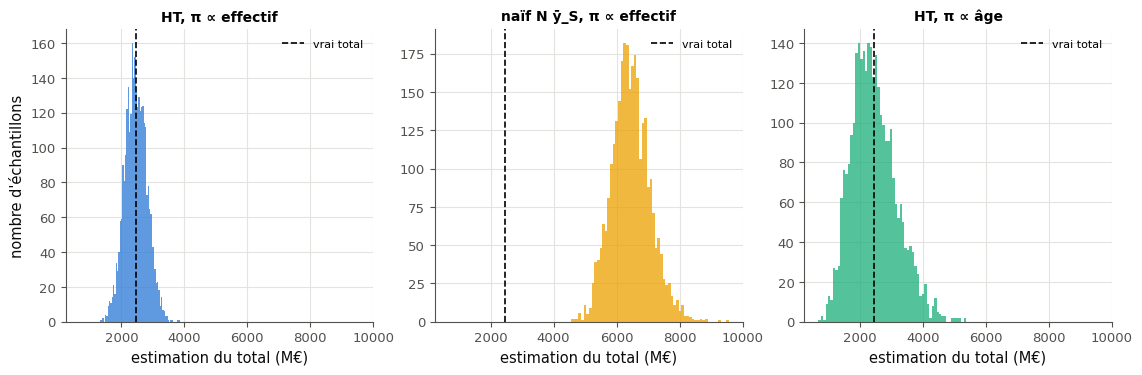

In [29]:
horvitz_thompson_total = mymath.tensors.horvitz_thompson_total
ht_14 = np.array([horvitz_thompson_total(Y_14, row, PI_14) for row in DRAWS_14])
naive_14 = np.array([N_14 * Y_14[row].mean() for row in DRAWS_14])
ht_age_14 = np.array([horvitz_thompson_total(Y_14, row, PI_AGE_14) for row in DRAWS_AGE_14])


def relative_14(values):
    """(relative bias, relative standard deviation, standard error of the bias), as fractions of the total."""
    spread = values.std(ddof=1) / TOTAL_14
    return values.mean() / TOTAL_14 - 1, spread, spread / math.sqrt(len(values))


bias_14, spread_14, error_14 = relative_14(ht_14)
answer_M20_14a = 100 * spread_14
answer_M20_14b = 100 * relative_14(ht_age_14)[1]
answer_M20_14c = 100 * relative_14(naive_14)[0]
answer_M20_14d = bool(abs(bias_14) < 3 * error_14)
sizes_14 = DRAWS_14.sum(axis=1)
print("taille des échantillons : de", sizes_14.min(), "à", sizes_14.max(), "; effectif moyen tiré :",
      round(float(np.mean([X_14[row].mean() for row in DRAWS_14])), 1), "contre", round(X_14.mean(), 1),
      "dans la population")
for label_14, pi_s14 in (("π ∝ effectif", PI_14), ("π ∝ âge", PI_AGE_14)):
    ratios_14 = Y_14 / pi_s14
    print(f"yᵢ/πᵢ, {label_14} : écart type relatif sur la population {np.std(ratios_14) / np.mean(ratios_14):.3f} ; "
          f"variance de la fiche : écart type relatif {math.sqrt(np.sum(Y_14 ** 2 * (1 - pi_s14) / pi_s14)) / TOTAL_14:.4f}")
print("biais relatif de ht_14 :", f"{100 * bias_14:.2f} %, soit {bias_14 / error_14:.2f} erreurs types ; de ht_age_14 :",
      f"{100 * relative_14(ht_age_14)[0]:.2f} %")
show_table_14 = True

with checked("M20.14"):
    if not filled(ht_14, naive_14, ht_age_14):
        print("⏳ Ex M20.14 : le tableau et la figure attendent tes trois tableaux, ht_14, naive_14 et ht_age_14.")
        raise StopCheck
    want_14 = {"ht_14": DRAWS_14 @ (Y_14 / PI_14),
               "naive_14": N_14 * (DRAWS_14 @ Y_14) / DRAWS_14.sum(axis=1),
               "ht_age_14": DRAWS_AGE_14 @ (Y_14 / PI_AGE_14)}
    ok_14 = [same("M20.14", f"{name} (une estimation par ligne de {rows})", got, want_14[name], rtol=1e-9, atol=1e-9)
             for name, rows, got in (("ht_14", "DRAWS_14", ht_14), ("naive_14", "DRAWS_14", naive_14),
                                     ("ht_age_14", "DRAWS_AGE_14", ht_age_14))]
    if not all(ok_14):
        raise StopCheck
    rows_14 = []
    for name_f14, values_f14 in (("HT, π ∝ effectif", ht_14), ("naïf N ȳ_S", naive_14), ("HT, π ∝ âge", ht_age_14)):
        values_f14 = np.asarray(values_f14, dtype=float)
        spread_f14 = values_f14.std(ddof=1) / TOTAL_14
        rows_14.append((name_f14, 100 * (values_f14.mean() / TOTAL_14 - 1), 100 * spread_f14,
                        100 * spread_f14 / math.sqrt(len(values_f14))))
    if show_table_14:                                  # only once the four answers are right: it shows them
        print(f"{'estimateur':18} {'biais relatif':>14} {'écart type relatif':>19} {'erreur type':>12}")
        for name_f14, bias_f14, spread_f14, error_f14 in rows_14:
            print(f"{name_f14:18} {bias_f14:13.2f} % {spread_f14:17.2f} % {error_f14:10.2f} %")
    else:
        print("ℹ️ Le tableau des biais et des écarts types relatifs s'affichera quand tes quatre réponses seront justes.")
    fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.8), sharex=True)
    try:
        for ax, (name_f14, values_f14), color_f14 in zip(axes, (("HT, π ∝ effectif", ht_14), ("naïf N ȳ_S, π ∝ effectif",
                                                                                              naive_14),
                                                                ("HT, π ∝ âge", ht_age_14)), ("C0", "C3", "C2")):
            ax.hist(np.asarray(values_f14, dtype=float), bins=60, color=color_f14, alpha=0.75)
            ax.axvline(TOTAL_14, color="k", ls="--", lw=1.2, label="vrai total")
            ax.set_title(name_f14, fontsize=10)
            ax.set_xlabel("estimation du total (M€)")
            ax.legend(fontsize=8)
        axes[0].set_ylabel("nombre d'échantillons")
    except BaseException:
        plt.close(fig)
        raise
    plt.show()

In [30]:
rng_14r = np.random.default_rng(5336)
x_14r = np.round(np.exp(rng_14r.normal(np.log(25), 1.2, size=400))) + 1
y_14r = np.round(0.12 * x_14r * np.exp(rng_14r.normal(0, 0.3, size=400)), 2)
age_14r = np.round(rng_14r.uniform(2, 30, size=400))
pi_14r = np.minimum(1.0, 40 * x_14r / x_14r.sum())
pi_age_14r = pi_14r.sum() * age_14r / age_14r.sum()
draws_14r = rng_14r.random((3000, 400)) < pi_14r
draws_age_14r = rng_14r.random((3000, 400)) < pi_age_14r
total_14r = y_14r.sum()
ht_14r = (draws_14r * (y_14r / pi_14r)).sum(axis=1)
naive_14r = 400 * (draws_14r * y_14r).sum(axis=1) / draws_14r.sum(axis=1)
age_ht_14r = (draws_age_14r * (y_14r / pi_age_14r)).sum(axis=1)
wbm.record("M20.14a", 100 * ht_14r.std(ddof=1) / total_14r, decimals=2,
           mistakes={"l'écart type des estimations de ht_14, pas celui de ht_age_14":
                         100 * age_ht_14r.std(ddof=1) / total_14r})
wbm.record("M20.14b", 100 * age_ht_14r.std(ddof=1) / total_14r, decimals=2,
           mistakes={"l'écart type des estimations de ht_age_14, pas celui de ht_14": 100 * ht_14r.std(ddof=1) / total_14r})
wbm.record("M20.14c", 100 * (naive_14r.mean() / total_14r - 1), decimals=1,
           mistakes={"le biais relatif est m/Y − 1, en % : retire 1 avant de multiplier par 100":
                         100 * naive_14r.mean() / total_14r})
assert abs(ht_14r.mean() / total_14r - 1) < 3 * ht_14r.std(ddof=1) / total_14r / math.sqrt(3000)
wbm.record("M20.14d", True,
           mistakes={"compare |m/Y − 1| à 3 s/(Y√3 000), avec les estimations de ht_14": False})

WBM_ANSWER {"coarse_any": {"0": ["94f0277070006fc404bf53cca6e205e24f8a99c221f9edb9ca71bda03a710889"]}, "decimals": 2, "hash": "ab725d6ae5a052d1e0518a77951fa619883d89b407bee44a4328030620878734", "hash_coarse": "011b65c0ce3a0de110f8c28b4ef8ee93a78d2c1dfeb4e5435f86cdeb4be2e9e5", "id": "M20.14a", "kind": "float", "magnitude": 1, "mistakes": {"c53ab51823fbbe8e4f43bd7f17f074371de75c14efc59261d645213a539983bf": "l'écart type des estimations de ht_14, pas celui de ht_age_14"}, "sign": 1}
📝 Ex M20.14a : réponse enregistrée (float, 2 décimales).
WBM_ANSWER {"coarse_any": {"0": ["b57ce49d10ac6c6911c02212ea976909bdad288214f007c24f4b293a6d398fe3"]}, "decimals": 2, "hash": "12816048d16d2ac103bdd687bbbf98c9d8c5c1104f89836465c21ac251232890", "hash_coarse": "d2f031cbccf8d23105cbb8d64d00258f32330d41b4d4e429cf022e63d4291d0c", "id": "M20.14b", "kind": "float", "magnitude": 1, "mistakes": {"50f1c1b247e86bcae4696511d3f2179ce084be475f6d76005b3a79f223917362": "l'écart type des estimations de ht_age_14, pas ce

**Après la figure**, dans ta copie : pourquoi l'estimateur naïf surestime-t-il autant (compare l'effectif moyen des entreprises tirées à celui de la population) ? Les deux estimateurs de Horvitz-Thompson sont sans biais : pourquoi `ht_14` est-il deux fois plus précis que `ht_age_14` ? Que vaut à peu près $y_i/\pi_i$ avec $\pi_i \propto x_i$, et avec $\pi_i$ proportionnel à l'âge (une jeune et grande entreprise, si elle est tirée) ? D'où vient l'écart type qui reste pour `ht_14` (pense au nombre d'entreprises tirées, qui change d'un échantillon à l'autre) ? Le défi M20.18 le fait disparaître.

💡 Les échantillons ont de 24 à 60 entreprises. Avec $\pi \propto$ effectif, l'effectif moyen des entreprises tirées est de 125 contre 47 dans la population : c) l'estimateur naïf surestime le total de 163,2 %. Horvitz-Thompson est sans biais dans les deux plans (biais relatifs de 0,44 % et de $-0{,}13$ %, d) à 1,7 erreur type pour `ht_14`), mais a) son écart type relatif vaut 14,27 % avec $\pi \propto$ effectif, contre b) 29,17 % avec $\pi$ proportionnel à l'âge ; la formule de la fiche donne 14,18 % et 29,45 %. Avec $\pi_i \propto x_i$, $y_i/\pi_i$ ne varie que de 30 % d'une entreprise à l'autre ; avec l'âge, de 170 % : une jeune et grande entreprise, rarement tirée, pèse énormément quand elle l'est. L'écart type qui reste pour `ht_14` vient surtout du nombre d'entreprises tirées, environ $\frac{1}{\sqrt{40}} \approx 16$ %.

### Ex M20.15 — Le produit de L jacobiennes I + hJ : ses valeurs singulières extrêmes quand L grandit, à hL fixé 🎨 ★ ⏱️ 20 min
**Objectif :** dessiner les valeurs singulières de $(\mathbf{I} + \frac TL\mathbf{J})^L$ quand $L$ grandit à horizon fixé, leur limite $e^{T\mathbf{J}}$ et les deux bornes de la fiche.  
**Prérequis :** fiche §6 ; M12d, M14 · **Parcours :** C, E

Un pas d'Euler pour $\mathbf{x}' = \mathbf{J}\mathbf{x}$ multiplie par $\mathbf{I} + h\mathbf{J}$ ; $L$ pas de durée $h = T/L$, à horizon $T$ fixé, multiplient par $(\mathbf{I} + \frac TL\mathbf{J})^L$, qui tend vers $e^{T\mathbf{J}}$ quand $L$ grandit (fiche §6). La cellule fournie donne $\mathbf{J} = \begin{pmatrix} -0{,}3 & -1{,}7 \\ 0{,}95 & -0{,}35 \end{pmatrix}$ (`J_15` : une rotation et une contraction), l'horizon $T = 2$ (`T_15`) et les onze nombres de pas $L = 1, 2, 4, \ldots, 1\,024$ (`LS_15`).

Écris `draw_products(ax, J, T, Ls)`, qui dessine dans l'axe `ax` (sans en ouvrir d'autre) :
- les deux valeurs singulières de $(\mathbf{I} + \frac TL\mathbf{J})^L$ en fonction de $L$, chacune par **une** ligne avec des points, une valeur par $L$ de `Ls`, dans l'ordre (`np.linalg.matrix_power`, puis `np.linalg.svd(..., compute_uv=False)`, qui les rend en ordre décroissant) ;
- les deux valeurs singulières de $e^{T\mathbf{J}}$ (`scipy.linalg.expm`), par deux droites horizontales (`ax.axhline`) ;
- en pointillés (`ls="--"`), les bornes de la fiche, avec $K = \lVert\mathbf{J}\rVert_2$ (`np.linalg.norm(J, 2)`) : la droite horizontale $e^{KT}$, et $(1 - hK)^L$ aux seuls $L$ de `Ls` pour lesquels $hK < 1$ (une ligne) ;
- $L$ en échelle logarithmique (`ax.set_xscale("log", base=2)`) ; une échelle logarithmique en ordonnée aussi, une légende et un titre.

Réponds :
- a) les deux valeurs singulières de $e^{T\mathbf{J}}$, en ordre décroissant (une liste, 4 décimales) ;
- b) la plus grande valeur singulière du produit pour $L = 1\,024$ (4 décimales) ;
- c) la borne $(1 - hK)^L$ pour $L = 16$, avec $h = T/L$ (4 décimales).

La vérification appelle ta fonction et regarde le dessin, dans cet ordre, en s'arrêtant au premier ❌ : les deux courbes, les deux droites de $e^{T\mathbf{J}}$, les deux bornes en pointillés (la borne basse aux seuls $L$ où $hK < 1$) et l'échelle logarithmique en $L$.

In [31]:
J_15 = np.array([[-0.3, -1.7],
                 [0.95, -0.35]])                # a rotation and a contraction
T_15 = 2.0                                      # the horizon
LS_15 = [2 ** k for k in range(11)]             # L = 1, 2, 4, ..., 1024

K = 1.7401 ; KT = 3.4802 ; e^(KT) = 32.467 ; e^(−KT) = 0.0308
a) [0.6165, 0.442] ; valeurs propres de J : [(-0.325+1.2706j), (-0.325-1.2706j)] ; e^(T Re λ) = 0.522
b) 0.6181  c) 0.0198 ; hK = 0.2175 ; la borne basse existe dès L = 4
L =    1 : [3.4247, 1.9213]
L =    2 : [2.6386, 1.6239]
L =    4 : [1.4228, 1.0479]
L =    8 : [0.9135, 0.6962]
L =   64 : [0.6431, 0.4666]
L = 1024 : [0.6181, 0.4435]
✅ draw_products dessine dans l'axe reçu
✅ les deux valeurs singulières du produit sont tracées en fonction de L
✅ les deux valeurs singulières de exp(TJ) sont des droites horizontales
✅ la borne e^(KT) est en pointillés
✅ la borne (1 − hK)^L est en pointillés, aux L où hK < 1
✅ la borne (1 − hK)^L n'est tracée qu'aux L où hK < 1
✅ L est en échelle logarithmique


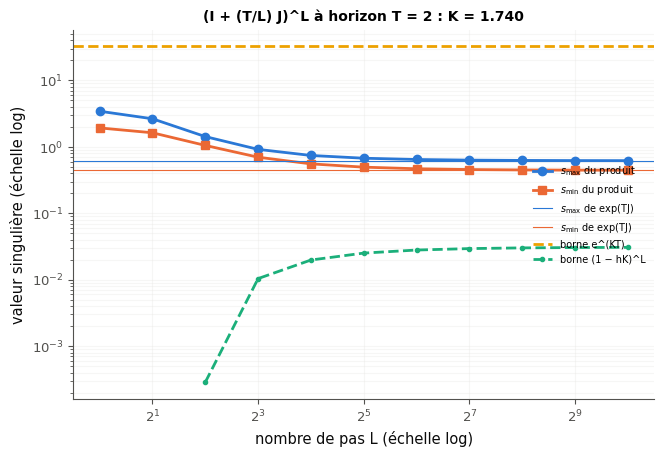

✅ Ex M20.15 : les deux courbes, leurs limites et les deux bornes sont dessinées.


In [32]:
def draw_products(ax, J, T, Ls):
    """In ax (and no other axes): the two singular values of (I + (T/L) J)^L against L (one line each, one point per
    L of Ls), those of expm(T J) as horizontal lines, the bounds e^(KT) and (1 − hK)^L (where hK < 1) dashed,
    K = ‖J‖₂ and h = T/L; L on a log scale."""
    J = np.asarray(J, dtype=float)
    K = np.linalg.norm(J, 2)
    identity = np.eye(len(J))
    values = np.array([np.linalg.svd(np.linalg.matrix_power(identity + (T / L) * J, L), compute_uv=False) for L in Ls])
    limit = np.linalg.svd(scipy.linalg.expm(T * J), compute_uv=False)
    ax.plot(Ls, values[:, 0], "o-", color="C0", label="$s_{\\max}$ du produit")
    ax.plot(Ls, values[:, -1], "s-", color="C1", label="$s_{\\min}$ du produit")
    ax.axhline(limit[0], color="C0", lw=0.8, label="$s_{\\max}$ de exp(TJ)")
    ax.axhline(limit[-1], color="C1", lw=0.8, label="$s_{\\min}$ de exp(TJ)")
    ax.axhline(math.exp(K * T), color="C3", ls="--", label="borne e^(KT)")
    lower = [(L, (1 - T / L * K) ** L) for L in Ls if T / L * K < 1]
    ax.plot([L for L, _ in lower], [v for _, v in lower], "--", color="C2", marker=".", label="borne (1 − hK)^L")
    ax.set_xscale("log", base=2)
    ax.set_yscale("log")
    ax.set_xlabel("nombre de pas L (échelle log)")
    ax.set_ylabel("valeur singulière (échelle log)")
    ax.set_title(f"(I + (T/L) J)^L à horizon T = {T:g} : K = {K:.3f}", fontsize=10)
    ax.grid(True, which="both", alpha=0.3)
    ax.legend(fontsize=7, loc="center right")


K_15 = np.linalg.norm(J_15, 2)
answer_M20_15a = np.linalg.svd(scipy.linalg.expm(T_15 * J_15), compute_uv=False).tolist()
answer_M20_15b = float(np.linalg.svd(np.linalg.matrix_power(np.eye(2) + (T_15 / 1024) * J_15, 1024), compute_uv=False)[0])
answer_M20_15c = (1 - T_15 / 16 * K_15) ** 16
print("K =", round(K_15, 4), "; KT =", round(K_15 * T_15, 4), "; e^(KT) =", round(math.exp(K_15 * T_15), 3),
      "; e^(−KT) =", round(math.exp(-K_15 * T_15), 4))
print("a)", np.round(answer_M20_15a, 4).tolist(), "; valeurs propres de J :", np.round(np.linalg.eigvals(J_15), 4).tolist(),
      "; e^(T Re λ) =", round(math.exp(T_15 * np.linalg.eigvals(J_15).real[0]), 4))
print("b)", round(answer_M20_15b, 4), " c)", round(answer_M20_15c, 4), "; hK =", round(T_15 / 16 * K_15, 4),
      "; la borne basse existe dès L =", min(L for L in LS_15 if T_15 / L * K_15 < 1))
for L in (1, 2, 4, 8, 64, 1024):
    print(f"L = {L:4d} :", np.round(np.linalg.svd(np.linalg.matrix_power(np.eye(2) + (T_15 / L) * J_15, L),
                                                  compute_uv=False), 4).tolist())

with checked("M20.15"):
    def report_15(ok, success, failure):
        """One ✅ line, or one ❌ line that stops the check there (the figure is still shown)."""
        print(("✅ " + success) if ok else ("❌ " + failure))
        if not ok:
            raise StopCheck

    K_c15 = np.linalg.norm(J_15, 2)
    values_c15 = np.array([np.linalg.svd(np.linalg.matrix_power(np.eye(2) + (T_15 / L) * J_15, L), compute_uv=False)
                           for L in LS_15])
    limit_c15 = np.linalg.svd(scipy.linalg.expm(T_15 * J_15), compute_uv=False)
    lower_c15 = [(L, (1 - T_15 / L * K_c15) ** L) for L in LS_15 if T_15 / L * K_c15 < 1]
    fig_15, ax_15 = plt.subplots(figsize=(7.5, 4.8))
    try:
        opened_15 = drawn(draw_products, ax_15, J_15.copy(), T_15, list(LS_15))
        lines_15 = [(np.asarray(line.get_xdata(), dtype=float), np.asarray(line.get_ydata(), dtype=float),
                     line.get_linestyle()) for line in ax_15.lines]

        def line_through_15(points, dashed=False):
            """The (xs, ys) of the first line of ax that passes by all the points (x, y), dashed or dotted when
            asked; None when there is none."""
            for xs, ys, style in lines_15:
                if dashed and style not in ("--", ":", "-."):
                    continue
                if xs.shape == ys.shape and all(np.any(np.isclose(xs, x, rtol=1e-9) & np.isclose(ys, y, rtol=1e-6))
                                                for x, y in points):
                    return xs, ys
            return None

        def level_15(value, dashed=False):
            """True when one line of ax is horizontal at value (ax.axhline, or a constant line)."""
            return any(ys.size >= 2 and np.all(np.isclose(ys[np.isfinite(ys)], value, rtol=1e-6))
                       and (not dashed or style in ("--", ":", "-.")) for _, ys, style in lines_15)

        report_15(not opened_15, "draw_products dessine dans l'axe reçu",
                  "draw_products doit dessiner dans l'axe reçu, sans ouvrir de figure (ni plt.figure ni plt.subplots)")
        report_15(line_through_15(list(zip(LS_15, values_c15[:, 0]))) is not None
                  and line_through_15(list(zip(LS_15, values_c15[:, 1]))) is not None,
                  "les deux valeurs singulières du produit sont tracées en fonction de L",
                  "il manque une courbe des valeurs singulières du produit (I + (T/L) J)^L : une ligne par valeur "
                  "singulière, une valeur par L de Ls")
        report_15(level_15(limit_c15[0]) and level_15(limit_c15[1]),
                  "les deux valeurs singulières de exp(TJ) sont des droites horizontales",
                  "il manque une droite horizontale aux valeurs singulières de scipy.linalg.expm(T * J) (ax.axhline)")
        report_15(level_15(math.exp(K_c15 * T_15), dashed=True), "la borne e^(KT) est en pointillés",
                  "il manque la borne e^(KT), K = np.linalg.norm(J, 2), en pointillés (ls=\"--\")")
        lower_line_15 = line_through_15(lower_c15, dashed=True)
        report_15(lower_line_15 is not None, "la borne (1 − hK)^L est en pointillés, aux L où hK < 1",
                  "il manque la borne (1 − hK)^L, h = T/L, en pointillés, aux L de Ls pour lesquels hK < 1")
        outside_15 = sorted({int(x) if float(x).is_integer() else float(x) for x, y in zip(*lower_line_15)
                             if np.isfinite(y) and (x <= 0 or T_15 / x * K_c15 >= 1)})
        report_15(not outside_15, "la borne (1 − hK)^L n'est tracée qu'aux L où hK < 1",
                  f"la borne (1 − hK)^L est aussi tracée pour L = {outside_15}, où hK ≥ 1 : la fiche ne la donne que "
                  "pour hK < 1, ne la trace qu'à ces L")
        report_15(ax_15.get_xscale() == "log", "L est en échelle logarithmique",
                  "mets L en échelle logarithmique : ax.set_xscale(\"log\", base=2)")
    except StopCheck:
        plt.show()
        raise
    except BaseException:
        plt.close(fig_15)
        raise
    plt.show()
    verdict("M20.15", True, "les deux courbes, leurs limites et les deux bornes sont dessinées.", "")

In [33]:
j_15r = np.array([[-0.3, -1.7], [0.95, -0.35]])
limit_15r = np.linalg.svd(scipy.linalg.expm(2.0 * j_15r), compute_uv=False)
eigen_15r = np.abs(np.linalg.eigvals(scipy.linalg.expm(2.0 * j_15r)))
wbm.record("M20.15a", limit_15r.tolist(), decimals=4,
           mistakes={"en ordre DÉCROISSANT, comme les rend np.linalg.svd": limit_15r[::-1].tolist(),
                     "les modules des valeurs propres de exp(TJ) ne sont pas ses valeurs singulières : J n'est pas "
                     "symétrique": eigen_15r.tolist()})
product_15r = np.linalg.svd(np.linalg.matrix_power(np.eye(2) + (2.0 / 1024) * j_15r, 1024), compute_uv=False)
wbm.record("M20.15b", float(product_15r[0]), decimals=4,
           mistakes={"le produit pour L = 1 024, pas sa limite exp(TJ)": float(limit_15r[0]),
                     "la PLUS GRANDE valeur singulière du produit": float(product_15r[1])})
k_15r = np.linalg.norm(j_15r, 2)
h_15r = 2.0 / 16
wbm.record("M20.15c", (1 - h_15r * k_15r) ** 16, decimals=4,
           mistakes={"la borne BASSE est (1 − hK)^L : le signe moins": (1 + h_15r * k_15r) ** 16,
                     "la borne pour L = 16, pas sa limite quand L grandit": math.exp(-2.0 * k_15r),
                     "h = T/L = 2/16 : n'oublie pas l'horizon T": (1 - k_15r / 16) ** 16})

WBM_ANSWER {"decimals": 4, "element_coarse": [["5130b4de786c140356570d171889e3fec6619d17ed97972403246073b53149d9"], ["fc125a826a6b7cd7a268eb8c17b6fc2996b24b6c43d7c409c97b909ec66a4862"]], "element_coarse_any": [["92bd70ebcfad84342eeca80482d05bf6e50aedfb8777840589cd3498dc8a162c", "f152554a0b1f6c0dbb20b4e96f702d4f52d39a432d026e97fa2d7ab512e328a6", "186aeddf7c8872d7b2328e3a510029189437e16fae1e0239c77f97a852e514ec"], ["dd02385b727e3f746b59bac1d6134b1e75f61f2bfda9eaed5b1f00919240d3b1", "a32c4724b8b74e6b8778a42e80bb1afdc82a3c28c012575bac226cd0aa99c3fe"]], "element_hashes": ["a2438f744af6180566515cb9e21a146e372c96e6abfc392d61be09920f52d7d3", "0dc484d34517afd86612707719c53ec23e638b5ddc3f1bada0761142422486f6"], "hash": "4e93d01d9dda68e79fc6ad08e8cabeb86579c96cc1aa619b76db9423368ce052", "id": "M20.15a", "kind": "array", "mistakes": {"2b4356b54761f396fa35d8a049dd898b7aef8fc16d1b28cc9ad30ea4a7048ae2": "en ordre DÉCROISSANT, comme les rend np.linalg.svd", "b58164807d69d65894e4fc3013306da9a31559fd9c0

**Pour aller plus loin** (facultatif). Le même dessin pour un champ non linéaire, l'oscillateur amorti $F(x, v) = (v,\ -x - x^3 - 0{,}3\,v)$ depuis $(1{,}2 ;\ 0)$, à horizon $T = 4$ : pour chaque $L$, le produit des jacobiennes $\mathbf{I} + h\mathbf{J}_F(\mathbf{x}_k)$ le long des points d'Euler $\mathbf{x}_0, \ldots, \mathbf{x}_{L-1}$, celle du dernier pas à gauche (fiche §6). Le notebook de solutions le trace.

**Dans ta copie** : pourquoi les deux courbes se stabilisent-elles quand $L$ grandit, alors que le nombre de facteurs double d'un point au suivant ? Pourquoi les valeurs singulières dépassent-elles 1 pour $L = 1$ et $L = 2$ (calcule $\lVert\mathbf{I} + 2\mathbf{J}\rVert$), et pourquoi les bornes sont-elles si loin des courbes ?

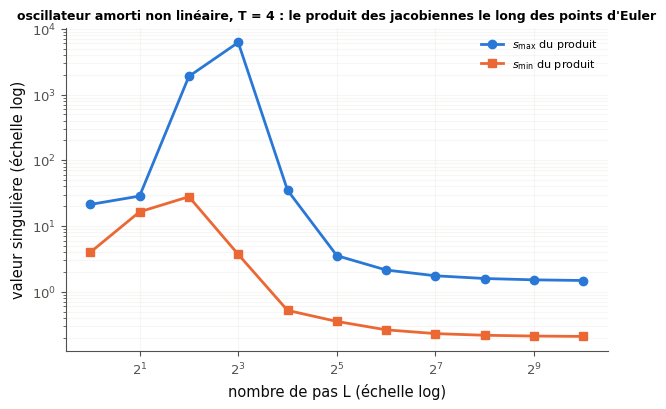

L = 1 024 : [1.4869, 0.2099] ; L = 512 : [1.5216, 0.2127]


In [34]:
def field_15(state):
    """The damped non-linear oscillator F(x, v) = (v, −x − x³ − 0.3 v)."""
    x, v = state
    return np.array([v, -x - x ** 3 - 0.3 * v])


def jacobian_15(state):
    """The Jacobian of field_15 at state."""
    x, _ = state
    return np.array([[0.0, 1.0], [-1.0 - 3.0 * x ** 2, -0.3]])


def euler_product_15(L, horizon=4.0, start=(1.2, 0.0)):
    """The product of the L Jacobians I + h J_F(x_k) along the Euler points, the last step on the left."""
    h, state, product_ = horizon / L, np.array(start, dtype=float), np.eye(2)
    for _ in range(L):
        product_ = (np.eye(2) + h * jacobian_15(state)) @ product_
        state = state + h * field_15(state)
    return product_


values_n15 = np.array([np.linalg.svd(euler_product_15(L), compute_uv=False) for L in LS_15])
fig, ax = plt.subplots(figsize=(7.0, 4.2))
ax.plot(LS_15, values_n15[:, 0], "o-", label="$s_{\\max}$ du produit")
ax.plot(LS_15, values_n15[:, 1], "s-", label="$s_{\\min}$ du produit")
ax.set_xscale("log", base=2)
ax.set_yscale("log")
ax.set_xlabel("nombre de pas L (échelle log)")
ax.set_ylabel("valeur singulière (échelle log)")
ax.set_title("oscillateur amorti non linéaire, T = 4 : le produit des jacobiennes le long des points d'Euler",
             fontsize=9)
ax.grid(True, which="both", alpha=0.3)
ax.legend(fontsize=8)
plt.show()
print("L = 1 024 :", np.round(values_n15[-1], 4).tolist(), "; L = 512 :", np.round(values_n15[-2], 4).tolist())

💡 $K = \lVert\mathbf{J}\rVert_2 \approx 1{,}7401$, $KT \approx 3{,}4802$ : la borne haute vaut $e^{KT} \approx 32{,}5$, et la borne basse croît avec $L$ vers $e^{-KT} \approx 0{,}031$. a) $e^{T\mathbf{J}}$ a pour valeurs singulières $0{,}6165$ et $0{,}4420$ (ses deux valeurs propres, de module $e^{-0{,}65} \approx 0{,}522$, ne sont pas ses valeurs singulières : $\mathbf{J}$ n'est pas symétrique). b) Pour $L = 1\,024$, $s_{\max} \approx 0{,}6181$, à $2 \cdot 10^{-3}$ de la limite. c) Pour $L = 16$, $hK = \frac{KT}{16} \approx 0{,}2175$ et $(1 - hK)^{16} \approx 0{,}0198$ ; la borne basse n'existe que pour $hK < 1$, ici dès $L = 4$. Pour $L = 1$ et $2$, les pas sont si grands que le produit étire : $\lVert\mathbf{I} + 2\mathbf{J}\rVert \approx 3{,}42$, puis $2{,}64$ ; dès $L = 8$, les deux courbes sont proches de leur limite ($0{,}9135$ et $0{,}6962$, puis $0{,}6431$ et $0{,}4666$ pour $L = 64$), et doubler $L$ ne les change presque plus. Les bornes valent pour toute matrice de norme $K$ et ignorent la rotation : elles sont larges, mais, à horizon fixé, la borne haute ne dépend pas de $L$, et la borne basse reste au-dessus de $e^{-2KT}$ dès que $hK \le \frac12$. Pour l'oscillateur non linéaire, le produit des jacobiennes se stabilise de même ($1{,}4869$ et $0{,}2099$ pour $L = 1\,024$).

## Partie C · Déboguer, tester

Fiche §2. Trois erreurs classiques des réductions le long d'axes ; un test de propriété pour les moments le long de deux axes. La vérification de M20.17 s'appuie sur la référence (`ref_tensors`), pour ne pas dépendre de ton code.

In [35]:
ref_tensors = wbm.load_mymath("ref", alias="mymath_ref").tensors   # the reference: the check of M20.17

### Ex M20.16 — Chasse à l'erreur : une moyenne sur le mauvais axe, une diffusion silencieuse, un ddof oublié 🐛 ★ ⏱️ 15 min
**Objectif :** reconnaître trois erreurs classiques des réductions le long d'axes qui ne lèvent aucune erreur Python et passent une vérification mal choisie, puis les corriger.  
**Prérequis :** fiche §2 · **Parcours :** C, E

Un collègue a écrit trois fonctions (cellule fournie) ; chacune a l'erreur que nomme le titre, aucune ne lève d'erreur Python, et chacune a passé la vérification qu'il a faite :
1. `subject_means_16(notes)` doit rendre la moyenne de chaque **matière** d'un tableau (élèves, matières). Il l'a vérifiée sur un tableau de 5 élèves et 5 matières : le résultat a bien la forme $(5,)$.
2. `noon_gap_16(T)` reçoit une journée de relevés, `T` de forme (stations, 24), et doit rendre l'écart moyen, sur les stations, entre le relevé de midi (l'heure 12) de chaque station et sa moyenne journalière, en valeur absolue : $\frac1n\sum_s \lvert T[s, 12] - \bar T_s\rvert$. Il l'a vérifiée sur quatre stations au même profil : la valeur attendue.
3. `sample_sd_16(x)` doit rendre l'écart type d'un échantillon de mesures répétées (l'incertitude d'une mesure), la racine de sa variance sans biais (ddof = 1). Il l'a vérifiée sur 100 000 tirages d'écart type 2 : à peu près 2.

À faire : écris `subject_means_16_fixed`, `noon_gap_16_fixed` et `sample_sd_16_fixed`, puis, avec elles (la valeur que donne le calcul, sans l'arrondir) :
- a) les moyennes des 3 matières du tableau `NOTES_16` (6 élèves, 3 matières ; une liste de 3 nombres) ;
- b) l'écart moyen de midi des 5 stations de `T_16` ;
- c) l'écart type des 5 mesures répétées d'une même longueur de `SMALL_16`, en mm.

La vérification essaie tes corrections sur des cas que tu ne vois pas : des tableaux de formes variées, des stations aux profils différents, de petits échantillons.

In [36]:
NOTES_16 = np.array([[12.0, 8.5, 15.0],
                     [9.5, 11.0, 13.0],
                     [14.0, 10.0, 16.5],
                     [7.0, 12.5, 11.0],
                     [15.5, 9.0, 14.0],
                     [10.0, 13.5, 12.0]])            # 6 pupils × 3 subjects
HOURS_16 = np.linspace(0.0, 23.0, 24)
rng_16 = np.random.default_rng(5332)
T_16 = np.round(np.array([[8.0], [12.5], [5.0], [15.0], [10.0]])
                + np.array([[3.0], [6.0], [2.0], [8.0], [4.5]]) * np.cos(2 * np.pi * (HOURS_16 - [[14], [15], [13], [16], [14]]) / 24)
                + rng_16.normal(0, 0.5, size=(5, 24)), 1)    # one day of 5 stations, hour by hour
SMALL_16 = np.array([12.5, 14.0, 9.5, 11.0, 13.0])     # five repeated measurements of one length, in mm


# The colleague's code
def subject_means_16(notes):
    """The mean of each subject of a table (pupils, subjects): one value per subject."""
    return notes.mean(axis=1)


def noon_gap_16(T):
    """T of shape (stations, 24): one day, hour by hour. The mean, over the stations, of |T[s, 12] − daily mean of s|."""
    return float(np.mean(np.abs(T[:, 12] - T.mean(axis=1, keepdims=True))))


def sample_sd_16(x):
    """The standard deviation of a sample: the square root of its unbiased variance (ddof = 1)."""
    return float(np.std(x))


# The colleague's checks: all pass
square_16 = np.round(np.random.default_rng(5332).uniform(5, 18, size=(5, 5)), 1)
print("(1) forme des moyennes d'un tableau de 5 élèves et 5 matières :", subject_means_16(square_16).shape,
      "(attendu (5,))")
profile_16 = 10 + 4 * np.cos(2 * np.pi * (HOURS_16 - 14) / 24)
print("(2) quatre stations au même profil :", round(noon_gap_16(np.tile(profile_16, (4, 1))), 6), "; attendu",
      round(abs(profile_16[12] - profile_16.mean()), 6))
print("(3) 100 000 tirages d'écart type 2 :", round(sample_sd_16(np.random.default_rng(5332).normal(15, 2, 100_000)), 2))

(1) forme des moyennes d'un tableau de 5 élèves et 5 matières : (5,) (attendu (5,))
(2) quatre stations au même profil : 3.464102 ; attendu 3.464102
(3) 100 000 tirages d'écart type 2 : 1.99


In [37]:
def subject_means_16_fixed(notes):
    """The mean of each subject of a table (pupils, subjects): one value per subject."""
    return np.asarray(notes, dtype=float).mean(axis=0)          # axis 0 runs over the pupils: one mean per column


def noon_gap_16_fixed(T):
    """T of shape (stations, 24): one day, hour by hour. The mean, over the stations, of |T[s, 12] − daily mean of s|."""
    T = np.asarray(T, dtype=float)
    return float(np.mean(np.abs(T[:, 12] - T.mean(axis=1))))     # (n,) − (n,): one gap per station


def sample_sd_16_fixed(x):
    """The standard deviation of a sample: the square root of its unbiased variance (ddof = 1)."""
    return float(np.std(x, ddof=1))


answer_M20_16a = subject_means_16_fixed(NOTES_16).tolist()
answer_M20_16b = noon_gap_16_fixed(T_16)
answer_M20_16c = sample_sd_16_fixed(SMALL_16)
print("a)", np.round(answer_M20_16a, 4).tolist(), "; le collègue :", np.round(subject_means_16(NOTES_16), 4).tolist())
print("b)", round(answer_M20_16b, 4), "; le collègue :", round(noon_gap_16(T_16), 4), "; forme de son tableau :",
      (T_16[:, 12] - T_16.mean(axis=1, keepdims=True)).shape)
print("c)", round(answer_M20_16c, 4), "; le collègue :", round(sample_sd_16(SMALL_16), 4), "; rapport √(5/4) =",
      round(math.sqrt(5 / 4), 4))


results_16, parts_16 = [], []


def report_16(ok, success, failure):
    results_16.append(bool(ok))
    print(("✅ " + success) if ok else ("❌ " + failure))


def call_16(part, name, function, *args):
    """function(*args); an error of the learner's code becomes one ❌ line that names the function (the check of this
    part stops there, the final verdict stays)."""
    try:
        return function(*args)
    except NotImplementedError:
        raise
    except Exception as exc:  # noqa: BLE001 - the learner's error, reported with the name of the function
        report_16(False, "", f"({part}) {name} : ton code lève {type(exc).__name__} : {str(exc)[:200]}")
        parts_16.append(part)
        raise StopCheck from None


def close_16(got, want):
    """True when got is a number (or an array of numbers) of the shape of want, equal to it up to rounding."""
    try:
        got = np.asarray(got, dtype=float)
    except (TypeError, ValueError):
        return False
    return got.shape == np.shape(want) and bool(np.allclose(got, want, rtol=1e-9, atol=1e-12))


with checked("M20.16"):                                       # (1) subject_means_16_fixed
    rng_c16 = np.random.default_rng(5332)
    wrong_16 = []
    for shape_c16 in ((7, 3), (4, 6), (5, 5), (12, 2)):
        notes_c16 = np.round(rng_c16.uniform(2, 19, size=shape_c16), 1)
        got_16 = call_16(1, "subject_means_16_fixed", subject_means_16_fixed, notes_c16.copy())
        want_16 = np.array([np.mean(notes_c16[:, j]) for j in range(shape_c16[1])])
        if got_16 is None or not close_16(got_16, want_16):
            wrong_16.append(f"un tableau {shape_c16[0]} × {shape_c16[1]} : attendu {np.round(want_16, 3).tolist()}, "
                            f"reçu {got_16!r}"[:220])
    report_16(not wrong_16, "(1) subject_means_16_fixed : quatre tableaux de formes variées",
              "(1) subject_means_16_fixed : " + " ; ".join(wrong_16[:2]))
    parts_16.append(1)

with checked("M20.16"):                                       # (2) noon_gap_16_fixed
    wrong_16 = []
    for n_c16 in (2, 3, 7):
        T_c16 = np.round(rng_c16.uniform(0, 20, size=(n_c16, 1)) + rng_c16.uniform(1, 8, size=(n_c16, 1))
                         * np.cos(2 * np.pi * (HOURS_16 - rng_c16.uniform(10, 18, size=(n_c16, 1))) / 24)
                         + rng_c16.normal(0, 1, size=(n_c16, 24)), 1)
        want_16 = float(np.mean([abs(T_c16[s, 12] - np.mean(T_c16[s])) for s in range(n_c16)]))
        got_16 = call_16(2, "noon_gap_16_fixed", noon_gap_16_fixed, T_c16.copy())
        if got_16 is None or not close_16(got_16, want_16):
            wrong_16.append(f"{n_c16} stations aux profils différents : attendu {want_16:.6g}, reçu {got_16!r}"[:200])
    report_16(not wrong_16, "(2) noon_gap_16_fixed : des stations aux profils différents",
              "(2) noon_gap_16_fixed : " + " ; ".join(wrong_16[:2]))
    parts_16.append(2)

with checked("M20.16"):                                       # (3) sample_sd_16_fixed
    wrong_16 = []
    for size_c16 in (2, 3, 5, 9, 40):
        x_c16 = np.round(rng_c16.normal(10, 3, size=size_c16), 2)
        want_16 = math.sqrt(sum((v - x_c16.mean()) ** 2 for v in x_c16) / (size_c16 - 1))
        got_16 = call_16(3, "sample_sd_16_fixed", sample_sd_16_fixed, x_c16.copy())
        if got_16 is None or not close_16(got_16, want_16):
            wrong_16.append(f"{size_c16} valeurs : attendu {want_16:.6g}, reçu {got_16!r}"[:160])
    report_16(not wrong_16, "(3) sample_sd_16_fixed : des échantillons de 2 à 40 valeurs",
              "(3) sample_sd_16_fixed : " + " ; ".join(wrong_16[:2]))
    parts_16.append(3)

if len(set(parts_16)) == 3:
    verdict("M20.16", all(results_16), "les trois fonctions corrigées passent tous les cas.",
            "relis les lignes ❌ ci-dessus.")

a) [11.3333, 10.75, 13.5833] ; le collègue : [11.8333, 11.1667, 13.5, 10.1667, 12.8333, 11.8333]
b) 3.1258 ; le collègue : 5.4125 ; forme de son tableau : (5, 5)
c) 1.7678 ; le collègue : 1.5811 ; rapport √(5/4) = 1.118
✅ (1) subject_means_16_fixed : quatre tableaux de formes variées
✅ (2) noon_gap_16_fixed : des stations aux profils différents
✅ (3) sample_sd_16_fixed : des échantillons de 2 à 40 valeurs
✅ Ex M20.16 : les trois fonctions corrigées passent tous les cas.


In [38]:
notes_16r = np.array([[12.0, 8.5, 15.0], [9.5, 11.0, 13.0], [14.0, 10.0, 16.5], [7.0, 12.5, 11.0],
                      [15.5, 9.0, 14.0], [10.0, 13.5, 12.0]])
wbm.record("M20.16a", [sum(notes_16r[:, j]) / 6 for j in range(3)], decimals=4,
           mistakes={"une valeur par élève : c'est l'axe 1 ; une matière est une colonne":
                         [sum(notes_16r[i]) / 3 for i in range(6)]})
hours_16r = np.linspace(0.0, 23.0, 24)
day_16r = np.round(np.array([[8.0], [12.5], [5.0], [15.0], [10.0]])
                   + np.array([[3.0], [6.0], [2.0], [8.0], [4.5]])
                   * np.cos(2 * np.pi * (hours_16r - [[14], [15], [13], [16], [14]]) / 24)
                   + np.random.default_rng(5332).normal(0, 0.5, size=(5, 24)), 1)
gaps_16r = [abs(day_16r[s, 12] - day_16r[s].mean()) for s in range(5)]
wbm.record("M20.16b", float(np.mean(gaps_16r)), decimals=4,
           mistakes={"(n,) moins (n, 1) donne (n, n) : retire à chaque station SA moyenne, un vecteur (n,) contre un "
                     "vecteur (n,)": float(np.mean(np.abs(day_16r[:, 12] - day_16r.mean(axis=1, keepdims=True))))})
small_16r = [12.5, 14.0, 9.5, 11.0, 13.0]
squares_16r = sum((v - sum(small_16r) / 5) ** 2 for v in small_16r)
wbm.record("M20.16c", math.sqrt(squares_16r / 4), decimals=4,
           mistakes={"ddof = 1 : la variance d'un échantillon divise par n − 1 ; np.std divise par n par défaut":
                         math.sqrt(squares_16r / 5),
                     "l'écart type est la RACINE de la variance": squares_16r / 4})

WBM_ANSWER {"decimals": 4, "element_coarse": [["3d61d57e6c287b4ebb8e76d6b8016d3bd97d05f52a710289b3f7313ef630620b"], ["1cf47694ba928516ab603a840d7de5f274edc0500accf46cfbdf351143cf88cd"], ["4c9177a439e80e204fb2043be42d4665892e212195ec83ed52429085c3bbabd2"]], "element_coarse_any": [["532363a1cf2d58d9dc4b476378e555e9cb1627caeecfde7e638638325233e797", "7b571eaabf405a24614f3ae38b97242b1fa0c90f162acc75cddd6f76c714094f", "b5cf4b1062ad29cedb57f4f92e8e2465ba1bb6981a8763e4a2f8477e1ff3b764"], ["360e0ae38b3c20aea7b6a6a969d1de9d2e4d55e5e89c8e12e4466407ea926357", "f8c76106376c2b6e25ecef39a3d1bc5d5367b97f40b64cc33eb6cfe0cd1adbb8", "44413ed5960adc106f3e182ae187a33248c5257d363405e70a2d510d1ce8dffa"], ["8b924c91223484d9a85a88d5e0c25b930183a9381f6702c26ca9cd090f0d6b3e", "b1e207577e0a8822648df24c83495a2809809eb5b274ac62d4772e768042485f", "b9091bd5352d5b86d5577857b5c7f3de7033b07bcd3440c24e33f08245983cc3"]], "element_hashes": ["48a04a9f07d06986ced86da0cbe3a57f055913d4bcf64b36556a17ed16410c84", "4ad8014a51ada

**Après la vérification**, dans ta copie : pourquoi la vérification (1) ne pouvait-elle pas voir l'erreur, et quelle vérification l'aurait vue ? Quelle est la forme de `T[:, 12] - T.mean(axis=1, keepdims=True)` pour 5 stations, et que contient sa case $(i, j)$ ? Pourquoi quatre stations au même profil cachent-elles l'erreur (2) ? Pour (3), de quel facteur le résultat du collègue s'écarte-t-il sur $n$ valeurs, et pourquoi ne le voit-on pas sur 100 000 ?

💡 (1) Sur un tableau carré, `axis=1` donne aussi 5 valeurs : la forme ne pouvait pas voir l'erreur ; il fallait comparer les valeurs, ou essayer un tableau non carré. a) Les moyennes des matières valent $[11{,}3333 ;\ 10{,}75 ;\ 13{,}5833]$ ; le collègue rend les 6 moyennes des élèves. (2) `T[:, 12] - T.mean(axis=1, keepdims=True)` a la forme $(5, 5)$ : sa case $(i, j)$ est $T[j, 12] - \bar T_i$. Quatre stations au même profil ont toutes la même moyenne et le même relevé de midi : les 16 cases sont égales, et la moyenne est juste par chance. b) L'écart moyen de midi vaut $3{,}1258$ ; le collègue trouve $5{,}4125$. (3) `np.std` divise par $n$ : le résultat est multiplié par $\sqrt{(n - 1)/n}$, un facteur $0{,}999995$ pour $n = 100\,000$, invisible, mais $0{,}894$ pour 5 mesures. c) $1{,}7678$ mm, contre $1{,}5811$ chez le collègue : un rapport $\sqrt{5/4} \approx 1{,}118$.

### Ex M20.17 — Un test de propriété : réduire sur deux axes d'un coup, ou l'un après l'autre 🛠️ ★ ⏱️ 25 min
**Objectif :** écrire un test de propriété pour les moments le long de deux axes, et s'assurer qu'il attrape trois fonctions fausses.  
**Prérequis :** fiche §2 ; Ex M20.11 · **Parcours :** C

Un **test de propriété** vérifie, sur beaucoup de cas tirés au hasard, une loi que tout résultat juste respecte, sans connaître la réponse de chaque cas (M17, M18). La loi, ici (fiche §2) : pour un tableau `x` et deux axes distincts $a$ et $b$,
- réduire sur $a$ et $b$ d'un coup, ou l'un après l'autre (d'abord $a$, puis $b$ sur le tableau des moyennes, les axes réduits étant gardés), donne la même **moyenne** ;
- la **variance** d'un coup, avec ddof = 0, est la moyenne, le long de $b$, des variances le long de $a$, plus la variance, le long de $b$, des moyennes le long de $a$ ;
- avec ddof = 1 partout, cette décomposition n'est plus exacte.

Écris deux fonctions, qui reçoivent la fonction à tester, `moments`, de même contrat que `moments_along_axes`. Toutes les réductions, d'un coup comme l'une après l'autre, passent par `moments` (au moins 4 appels par cas : la vérification les compte) :
- `check_two_axes(moments, x, a, b)` lève une `AssertionError` (un `assert` avec un message qui dit le cas) si les moyennes ne coïncident pas, ou si la décomposition de la variance avec ddof = 0 n'est pas exacte (`np.allclose`, `rtol=1e-9`, `atol=1e-12`) ; sinon, elle rend l'écart relatif de la même décomposition avec ddof = 1, $\frac{\lvert v_1 - (\text{moyenne des variances} + \text{variance des moyennes})\rvert}{v_1}$, le plus grand sur les valeurs des autres axes (un `float`) ;
- `property_test_17(moments)` tire 100 cas avec un générateur `np.random.default_rng(5337)`, créé dans la fonction : un tableau de 2 à 4 axes, de longueurs 2 à 5, de valeurs de loi normale, et deux axes distincts tirés au hasard ; elle rend la liste des 100 écarts de `check_two_axes`.

La cellule fournie donne trois fonctions **fausses**, construites sur la référence (`ref_tensors`) : `ignores_ddof_17` divise toujours par $N - 1$ ; `variance_of_variances_17` rend, le long de plusieurs axes, la moyenne des variances le long du premier ; `wrong_count_17` divise la somme le long de plusieurs axes par la longueur du premier seulement. La vérification lance ton test sur la référence, où il doit passer ; sur chacune des trois fonctions fausses, où il doit échouer par un `assert` ; puis sur **ta** `moments_along_axes`.

In [39]:
def ignores_ddof_17(x, axes, ddof=0):
    """Wrong: the variance always divides by N − 1, whatever ddof (built on the reference)."""
    return ref_tensors.moments_along_axes(x, axes, ddof=1)


def variance_of_variances_17(x, axes, ddof=0):
    """Wrong: along several axes, the variance is the mean, over the other reduced axes, of the variances along the
    first one (built on the reference)."""
    axes = (int(axes),) if np.ndim(axes) == 0 else tuple(int(a) for a in axes)
    mean, var = ref_tensors.moments_along_axes(x, axes, ddof=ddof)
    if len(axes) > 1:
        var = ref_tensors.moments_along_axes(ref_tensors.moments_along_axes(x, axes[0], ddof=ddof)[1], axes[1:])[0]
    return mean, var


def wrong_count_17(x, axes, ddof=0):
    """Wrong: along several axes, the sum is divided by the length of the first axis only (built on the reference)."""
    axes = (int(axes),) if np.ndim(axes) == 0 else tuple(int(a) for a in axes)
    mean, var = ref_tensors.moments_along_axes(x, axes, ddof=ddof)
    if len(axes) > 1:
        mean = mean * np.prod([np.shape(x)[a] for a in axes]) / np.shape(x)[axes[0]]
    return mean, var


WRONG_17 = {"ignores_ddof_17": ignores_ddof_17, "variance_of_variances_17": variance_of_variances_17,
            "wrong_count_17": wrong_count_17}

In [40]:
def check_two_axes(moments, x, a, b):
    """For the function under test moments (the contract of moments_along_axes): assert that the mean along (a, b)
    is the mean along a then b, and that the variance along (a, b) with ddof = 0 is the mean along b of the variances
    along a plus the variance along b of the means along a. Return the largest relative gap of the same decomposition
    with ddof = 1."""
    gaps = []
    for ddof in (0, 1):
        mean, var = moments(x, (a, b), ddof=ddof)
        mean_a, var_a = moments(x, a, ddof=ddof)                  # axis a kept with length 1: b does not move
        mean_ab, var_of_means = moments(mean_a, b, ddof=ddof)
        mean_of_vars, _ = moments(var_a, b, ddof=ddof)
        if ddof == 0:
            assert np.allclose(mean, mean_ab, rtol=1e-9, atol=1e-12), (
                f"shape {x.shape}, axes ({a}, {b}): the mean in one go differs from the mean along {a} then {b}")
            assert np.allclose(var, mean_of_vars + var_of_means, rtol=1e-9, atol=1e-12), (
                f"shape {x.shape}, axes ({a}, {b}): the variance (ddof = 0) is not the mean of the variances plus "
                f"the variance of the means")
        else:
            gaps.append(float(np.max(np.abs(var - (mean_of_vars + var_of_means)) / var)))
    return gaps[0]


def property_test_17(moments):
    """check_two_axes on 100 random cases drawn with np.random.default_rng(5337): arrays of 2 to 4 axes of lengths 2
    to 5, two distinct axes. Return the list of the 100 gaps."""
    rng = np.random.default_rng(5337)
    gaps = []
    for _ in range(100):
        shape = tuple(int(n) for n in rng.integers(2, 6, size=int(rng.integers(2, 5))))
        a, b = (int(axis) for axis in rng.choice(len(shape), size=2, replace=False))
        gaps.append(check_two_axes(moments, rng.normal(size=shape), a, b))
    return gaps


gaps_s17 = property_test_17(ref_tensors.moments_along_axes)
print("ddof = 1 : écart relatif de la décomposition, de", f"{min(gaps_s17):.1e}", "à", f"{max(gaps_s17):.1e}",
      "; médiane", f"{np.median(gaps_s17):.2f}")
for name_s17, wrong_s17 in WRONG_17.items():
    try:
        property_test_17(wrong_s17)
        print(name_s17, ": pas attrapée")
    except AssertionError as exc:
        print(name_s17, ":", exc)


with checked("M20.17"):
    results_17 = []

    def report_17(ok, success, failure):
        results_17.append(bool(ok))
        print(("✅ " + success) if ok else ("❌ " + failure))

    calls_17 = [0]

    def counted_17(function):
        """function, its calls counted in calls_17."""
        def wrapper(x, axes, ddof=0):
            calls_17[0] += 1
            return function(x, axes, ddof=ddof)
        return wrapper

    try:
        gaps_17 = property_test_17(counted_17(ref_tensors.moments_along_axes))
    except AssertionError as exc:
        print(f"❌ Ex M20.17 : ton test échoue sur la référence, qui est juste : {exc}"[:400])
        raise StopCheck from None
    try:
        gaps_17 = np.asarray(gaps_17, dtype=float).ravel()
    except (TypeError, ValueError):
        print(f"❌ Ex M20.17 : property_test_17 doit rendre la liste des écarts, reçu {gaps_17!r}"[:200])
        raise StopCheck from None
    report_17(calls_17[0] >= 400 and gaps_17.size >= 100,
              f"sur la référence, ton test passe : {gaps_17.size} cas, {calls_17[0]} appels de moments",
              f"sur la référence, ton test ne fait que {gaps_17.size} cas et {calls_17[0]} appels de moments : au moins "
              "100 cas, et au moins quatre appels par cas")
    report_17(gaps_17.size > 0 and np.all(np.isfinite(gaps_17)) and np.all(gaps_17 >= 0) and np.min(gaps_17) > 1e-9,
              f"avec ddof = 1, la décomposition n'est jamais exacte : écart relatif de {np.min(gaps_17):.1e} à "
              f"{np.max(gaps_17):.1e}" if gaps_17.size else "",
              "les écarts rendus avec ddof = 1 doivent être des nombres positifs, non nuls : |v₁ − (moyenne des "
              "variances + variance des moyennes)| / v₁")
    for name_17, wrong_function_17 in WRONG_17.items():
        try:
            property_test_17(wrong_function_17)
            outcome_17 = "il passe"
        except AssertionError:
            outcome_17 = None
        except Exception as exc:  # noqa: BLE001 - another error than an assert
            outcome_17 = f"il lève {type(exc).__name__} : {str(exc)[:120]}"
        report_17(outcome_17 is None, f"ton test attrape {name_17} par un assert",
                  f"ton test n'attrape pas {name_17} par un assert ({outcome_17})")
    try:
        property_test_17(mymath.tensors.moments_along_axes)
        mine_17 = None
    except AssertionError as exc:
        mine_17 = str(exc)[:200]
    print("✅ ta moments_along_axes passe ton test de propriété" if mine_17 is None else
          f"❌ ta moments_along_axes échoue à ton test ({mine_17}) : si ton test passe sur la référence, l'erreur est "
          "dans ta fonction (lance aussi les tests de M20.11)")
    verdict("M20.17", all(results_17), "ton test passe sur la référence et attrape les trois fonctions fausses.",
            "relis les lignes ❌ ci-dessus.")

ddof = 1 : écart relatif de la décomposition, de 1.3e-01 à 7.5e-01 ; médiane 0.33
ignores_ddof_17 : shape (3, 3), axes (0, 1): the variance (ddof = 0) is not the mean of the variances plus the variance of the means
variance_of_variances_17 : shape (3, 3), axes (0, 1): the variance (ddof = 0) is not the mean of the variances plus the variance of the means
wrong_count_17 : shape (3, 3), axes (0, 1): the mean in one go differs from the mean along 0 then 1
✅ sur la référence, ton test passe : 100 cas, 800 appels de moments
✅ avec ddof = 1, la décomposition n'est jamais exacte : écart relatif de 1.3e-01 à 7.5e-01
✅ ton test attrape ignores_ddof_17 par un assert
✅ ton test attrape variance_of_variances_17 par un assert
✅ ton test attrape wrong_count_17 par un assert
✅ ta moments_along_axes passe ton test de propriété
✅ Ex M20.17 : ton test passe sur la référence et attrape les trois fonctions fausses.


**Après la vérification**, dans ta copie : écris la décomposition pour un tableau de forme $(n_a, n_b)$ et démontre-la (le terme croisé s'annule). Avec ddof = 1, quels dénominateurs apparaissent, et pourquoi ne se recombinent-ils pas ? Laquelle des trois fonctions fausses la propriété des moyennes attrape-t-elle, et lesquelles seule la décomposition attrape-t-elle ? Une fonction qui calcule la variance par « moyenne des carrés moins carré de la moyenne » passerait-elle ton test, et que verraient les tests de `mymath` ?

💡 Pour un tableau $(n_a, n_b)$, la somme des carrés des écarts à la moyenne générale se coupe en celle des écarts à la moyenne de chaque colonne plus $n_a$ fois celle des écarts des moyennes de colonnes à la moyenne générale (le terme croisé est nul, puisque les écarts à une moyenne ont pour somme 0) ; divisée par $n_an_b$, c'est la décomposition. Avec ddof = 1, les trois termes se divisent par $n_an_b - 1$, $n_a - 1$ et $n_b - 1$, qui ne se recombinent pas : sur les 100 cas, l'écart relatif va de 0,13 à 0,75 (médiane 0,33). Les trois fonctions fausses sont attrapées dès le premier cas, un tableau $3 \times 3$ : `wrong_count_17` par la propriété des moyennes, `ignores_ddof_17` et `variance_of_variances_17` par la seule décomposition, leurs moyennes étant justes. Une variance par « moyenne des carrés moins carré de la moyenne » passerait ce test sur des valeurs de loi normale centrée ; les tests de `mymath` l'attrapent, sur des valeurs de l'ordre de $10^8$.

## Partie D · Défi

Fiche §5. Des probabilités proportionnelles à la taille, plafonnées à 1, et un tirage systématique : un estimateur sans biais et presque sans variance.

### Ex M20.18 — Défi : des probabilités d'inclusion proportionnelles à la taille, et un estimateur presque sans variance 🏆 ★★★ ⏱️ 25 min
**Objectif :** construire des probabilités d'inclusion proportionnelles à une taille, plafonnées à 1, et mesurer avec un tirage systématique la précision qu'elles donnent à l'estimateur de Horvitz-Thompson.  
**Prérequis :** fiche §5 ; Ex M20.12 et M20.14 · **Parcours :** C

Une population de $N = 150$ communes (cellule fournie) : leur population au dernier recensement, $x_i$ (`X_18`, connue ; quelques très grandes villes), et leur population actuelle, $y_i$, à quelques pour cent près la même (`Y_18`, inconnue de celui qui sonde ; le vrai total est `TOTAL_18`). On veut estimer le total en visitant $n = 21$ communes (`n_18`).

La cellule fournie donne aussi `systematic_sample(pi, rng)`, le **tirage systématique** : on aligne les $\pi_i$ bout à bout sur un segment de longueur $n = \sum_i\pi_i$, on tire $u$ uniforme dans $[0, 1[$ (un seul `rng.random()` par appel), et l'on prend les unités dont l'intervalle contient l'un des points $u, u + 1, \ldots, u + n - 1$. Chaque unité est tirée avec la probabilité $\pi_i$, et **exactement** $n$ unités le sont ; elle refuse (`ValueError`) un $\pi_i$ hors de $]0, 1]$ ou une somme qui n'est pas entière.

Écris `pps_probabilities(x, n)` : des probabilités proportionnelles à $x$, de somme $n$. Une unité dont la probabilité dépasserait 1 est prise d'office ($\pi_i = 1$), et le reste, $n$ moins le nombre d'unités prises d'office, est réparti à nouveau, proportionnellement à $x$, entre les autres ; on recommence jusqu'à ce qu'aucune ne dépasse 1. Un tableau de flottants ; `x` n'est pas modifié.

Puis, avec tes probabilités `pi_18` pour `X_18` et `n_18` :
- `estimates_18` : les 2 000 estimations de Horvitz-Thompson de 2 000 tirages systématiques, faits avec un générateur `np.random.default_rng(5339)` créé une fois, un appel de `systematic_sample` par tirage ;
- `equal_18` : de même, avec les probabilités égales $n/N$ et un second générateur `np.random.default_rng(5339)`.

Réponds :
- a) le nombre de communes prises d'office ($\pi_i = 1$) ;
- b) l'écart type relatif de `estimates_18`, en % (l'écart type avec ddof = 1, divisé par le vrai total ; la valeur que donne le calcul, sans l'arrondir) ;
- c) celui de `equal_18`, en % (la valeur que donne le calcul, sans l'arrondir).

La vérification essaie `pps_probabilities` sur d'autres populations et regarde la somme, l'intervalle $]0, 1]$ et les communes prises d'office ; puis elle refait la simulation avec tes probabilités : l'écart type relatif doit rester sous 2 %, celui des probabilités égales dépasser 10 %, et le biais relatif rester sous 3 erreurs types.

In [41]:
rng_18 = np.random.default_rng(5338)
N_18, n_18 = 150, 21                                                       # 150 communes, a sample of 21
X_18 = np.round(np.exp(rng_18.normal(np.log(2500), 1.5, size=N_18)))      # the population at the last census: known
Y_18 = np.round(X_18 * (1 + rng_18.normal(0.03, 0.04, size=N_18)))        # the population today: unknown
TOTAL_18 = Y_18.sum()                                                      # the true total, to judge the estimates


def systematic_sample(pi, rng):
    """The systematic draw: the π_i laid end to end on a segment of length n = Σ π_i (an integer), u drawn uniform in
    [0, 1[ (one rng.random() per call), and the units whose interval holds one of the points u, u + 1, ..., u + n − 1.
    Each unit is drawn with the probability π_i, and exactly n units are. Returns a boolean array."""
    pi = np.asarray(pi, dtype=float)
    if pi.ndim != 1 or np.any(~(pi > 0)) or np.any(pi > 1 + 1e-12):
        raise ValueError("every π_i must be in ]0, 1]")
    n = pi.sum()
    if abs(n - round(n)) > 1e-9:
        raise ValueError(f"the sum of the π_i must be an integer, got {n!r}")
    bounds = np.concatenate([[0.0], np.cumsum(pi)])
    bounds *= round(n) / bounds[-1]                                         # exactly n at the end
    points = rng.random() + np.arange(round(n))
    units = np.minimum(np.searchsorted(bounds, points, side="right") - 1, len(pi) - 1)
    included = np.zeros(len(pi), dtype=bool)
    included[units] = True
    return included


print("les 5 plus grandes communes :", np.sort(X_18)[-5:].astype(int).tolist(), "; total au recensement :",
      int(X_18.sum()), "; n x_i / Σx > 1 pour", int(np.sum(n_18 * X_18 / X_18.sum() > 1)), "commune(s)")

les 5 plus grandes communes : [40615, 46492, 52480, 79056, 100589] ; total au recensement : 1048929 ; n x_i / Σx > 1 pour 3 commune(s)


In [42]:
def pps_probabilities(x, n):
    """Inclusion probabilities proportional to x, of sum n: a unit whose probability would exceed 1 is taken with
    certainty (π = 1), and what remains of n is shared again among the others in proportion to x, until none
    exceeds 1. Returns a new array of floats."""
    x = np.asarray(x, dtype=float)
    certain = np.zeros(len(x), dtype=bool)
    while True:
        rest = ~certain
        pi = np.where(certain, 1.0, (n - certain.sum()) * x / x[rest].sum())
        over = rest & (pi > 1)
        if not over.any():
            return pi
        certain |= over                                         # taken with certainty; share the rest again


def simulate_18(probabilities, draws=2000):
    """The Horvitz-Thompson estimates of `draws` systematic draws, one generator np.random.default_rng(5339)."""
    rng = np.random.default_rng(5339)
    estimates = np.empty(draws)
    for k in range(draws):
        drawn = systematic_sample(probabilities, rng)
        estimates[k] = np.sum(Y_18[drawn] / probabilities[drawn])
    return estimates


pi_18 = pps_probabilities(X_18, n_18)
estimates_18 = simulate_18(pi_18)
equal_18 = simulate_18(np.full(N_18, n_18 / N_18))
answer_M20_18a = int(np.sum(pi_18 == 1))
answer_M20_18b = 100 * estimates_18.std(ddof=1) / TOTAL_18
answer_M20_18c = 100 * equal_18.std(ddof=1) / TOTAL_18
print("dépassent 1 avant toute répartition :", int(np.sum(n_18 * X_18 / X_18.sum() > 1)), "; prises d'office à la fin :",
      answer_M20_18a, "; les π suivants :", np.round(np.sort(pi_18[pi_18 < 1])[-3:], 4).tolist())
print("yᵢ/πᵢ des communes qui ne sont pas prises d'office : de", round(float(np.min((Y_18 / pi_18)[pi_18 < 1]))),
      "à", round(float(np.max((Y_18 / pi_18)[pi_18 < 1]))))
print("b)", round(answer_M20_18b, 2), "% ; biais relatif :", f"{100 * (estimates_18.mean() / TOTAL_18 - 1):.3f} %")
print("c)", round(answer_M20_18c, 1), "% ; biais relatif :", f"{100 * (equal_18.mean() / TOTAL_18 - 1):.2f} %")


with checked("M20.18"):
    results_18 = []

    def report_18(ok, success, failure):
        results_18.append(bool(ok))
        print(("✅ " + success) if ok else ("❌ " + failure))

    def expected_18(x, n):
        """min(1, c x), with c such that Σ min(1, c x) = n, by bisection: another method than the statement's."""
        low, high = 0.0, 1.0 / np.min(x)
        for _ in range(200):
            middle = (low + high) / 2
            low, high = (middle, high) if np.minimum(1.0, middle * x).sum() < n else (low, middle)
        return np.minimum(1.0, high * x)

    rng_c18 = np.random.default_rng(5338)
    cases_18 = [("la population de l'énoncé", X_18, n_18)]
    for size_c18, count_c18, spread_c18 in ((30, 6, 1.6), (60, 12, 0.3), (80, 9, 2.0), (12, 11, 1.0)):
        cases_18.append((f"{size_c18} unités, n = {count_c18}",
                         np.round(np.exp(rng_c18.normal(5, spread_c18, size=size_c18))) + 1, count_c18))
    wrong_18 = []
    for label_c18, x_c18, n_c18 in cases_18:
        copy_c18 = x_c18.copy()
        got_c18 = pps_probabilities(copy_c18, n_c18)
        want_c18 = expected_18(x_c18, n_c18)
        if not np.array_equal(copy_c18, x_c18):
            wrong_18.append(f"{label_c18} : x a été modifié")
        elif got_c18 is None or np.shape(got_c18) != x_c18.shape:
            wrong_18.append(f"{label_c18} : attendu un tableau de forme {x_c18.shape}, reçu {got_c18!r}"[:160])
        elif not np.allclose(np.asarray(got_c18, dtype=float), want_c18, rtol=1e-9, atol=1e-12):
            got_c18 = np.asarray(got_c18, dtype=float)
            wrong_18.append(f"{label_c18} : ce ne sont pas les probabilités attendues (somme attendue {n_c18}, reçu "
                            f"une somme {got_c18.sum():.6g} et un plus grand π de {got_c18.max():.6g})")
    report_18(not wrong_18, f"pps_probabilities : juste sur {len(cases_18)} populations", "pps_probabilities, "
              + " ; ".join(wrong_18[:2]))
    if wrong_18:
        raise StopCheck
    pi_c18 = np.asarray(pps_probabilities(X_18, n_18), dtype=float)
    certain_c18 = pi_c18 >= 1 - 1e-12
    report_18(abs(pi_c18.sum() - n_18) < 1e-9 and np.all((pi_c18 > 0) & (pi_c18 <= 1 + 1e-12)),
              f"tes probabilités sont dans ]0, 1] et ont pour somme {n_18}", "tes probabilités doivent être dans ]0, 1] "
              f"et avoir pour somme {n_18}")
    report_18(certain_c18.any() and X_18[certain_c18].min() > X_18[~certain_c18].max(),
              "les communes prises d'office sont les plus grandes",
              "les communes prises d'office doivent être les plus grandes")
    pi_c18 = np.where(certain_c18, 1.0, pi_c18)
    equal_c18 = np.full(N_18, n_18 / N_18)
    for label_c18, probabilities_c18 in (("tes probabilités", pi_c18), ("des probabilités égales", equal_c18)):
        rng_s18 = np.random.default_rng(5339)
        estimates_c18 = np.empty(2000)
        for k_c18 in range(2000):
            drawn_c18 = systematic_sample(probabilities_c18, rng_s18)
            estimates_c18[k_c18] = np.sum(Y_18[drawn_c18] / probabilities_c18[drawn_c18])
        spread_c18 = estimates_c18.std(ddof=1) / TOTAL_18
        bias_c18 = estimates_c18.mean() / TOTAL_18 - 1
        if probabilities_c18 is pi_c18:
            report_18(spread_c18 < 0.02, f"avec {label_c18}, l'écart type relatif reste sous 2 %",
                      f"avec {label_c18}, l'écart type relatif dépasse 2 %")
            report_18(abs(bias_c18) < 3 * spread_c18 / math.sqrt(2000),
                      "le biais relatif reste sous 3 erreurs types", "le biais relatif dépasse 3 erreurs types")
        else:
            report_18(spread_c18 > 0.10, f"avec {label_c18}, l'écart type relatif dépasse 10 %",
                      f"avec {label_c18}, l'écart type relatif reste sous 10 %")
    verdict("M20.18", all(results_18), "tes probabilités rendent l'estimation de Horvitz-Thompson presque exacte.",
            "relis les lignes ❌ ci-dessus.")

dépassent 1 avant toute répartition : 3 ; prises d'office à la fin : 4 ; les π suivants : [0.7657, 0.8321, 0.8963]
yᵢ/πᵢ des communes qui ne sont pas prises d'office : de 41391 à 50919
b) 0.42 % ; biais relatif : 0.008 %
c) 34.2 % ; biais relatif : 0.24 %
✅ pps_probabilities : juste sur 5 populations
✅ tes probabilités sont dans ]0, 1] et ont pour somme 21
✅ les communes prises d'office sont les plus grandes


✅ avec tes probabilités, l'écart type relatif reste sous 2 %
✅ le biais relatif reste sous 3 erreurs types


✅ avec des probabilités égales, l'écart type relatif dépasse 10 %
✅ Ex M20.18 : tes probabilités rendent l'estimation de Horvitz-Thompson presque exacte.


In [43]:
rng_18r = np.random.default_rng(5338)
x_18r = np.round(np.exp(rng_18r.normal(np.log(2500), 1.5, size=150)))
y_18r = np.round(x_18r * (1 + rng_18r.normal(0.03, 0.04, size=150)))
order_18r = np.argsort(x_18r)[::-1]                 # the largest first: k certain units, c = (n − k) / Σ of the others
for k_18r in range(21):
    c_18r = (21 - k_18r) / x_18r[order_18r[k_18r:]].sum()
    if c_18r * x_18r[order_18r[k_18r]] <= 1:
        break
pi_18r = np.minimum(1.0, c_18r * x_18r)
assert abs(pi_18r.sum() - 21) < 1e-9 and int(np.sum(21 * x_18r / x_18r.sum() > 1)) < k_18r
wbm.record("M20.18a", k_18r,
           mistakes={"on recommence : après une répartition, d'autres communes peuvent dépasser 1":
                         int(np.sum(21 * x_18r / x_18r.sum() > 1))})


def systematic_18r(pi, rng):
    bounds = np.concatenate([[0.0], np.cumsum(pi)])
    bounds *= round(pi.sum()) / bounds[-1]
    units = np.minimum(np.searchsorted(bounds, rng.random() + np.arange(round(pi.sum())), side="right") - 1, len(pi) - 1)
    return units


def spread_18r(pi):
    rng = np.random.default_rng(5339)
    estimates = []
    for _ in range(2000):
        units = systematic_18r(pi, rng)
        estimates.append(np.sum(y_18r[units] / pi[units]))
    return 100 * np.std(estimates, ddof=1) / y_18r.sum()


wbm.record("M20.18b", spread_18r(pi_18r), decimals=2,
           mistakes={"l'écart type des estimations faites avec TES probabilités, pas avec les probabilités égales":
                         spread_18r(np.full(150, 21 / 150)),
                     "un écart type nul : tes tirages sont identiques ; crée le générateur une seule fois, avant la "
                     "boucle": 0.0})
wbm.record("M20.18c", spread_18r(np.full(150, 21 / 150)), decimals=1)

WBM_ANSWER {"hash": "94afcbcea47623c08e56cbbc86c30645e69eef8f77b8fdfa7736c462ef6db3b8", "id": "M20.18a", "kind": "int", "magnitude": 0, "mistakes": {"744a991dcf6c2f80e9810af10ac8d0342fc0b0309d002e6ac3c32c14a35feb56": "on recommence : après une répartition, d'autres communes peuvent dépasser 1"}, "sign": 1}
📝 Ex M20.18a : réponse enregistrée (int).
WBM_ANSWER {"decimals": 2, "hash": "1b1b7ecc9628f7b574c01ac3e60bc0907f496941ab67e1dd64f4fd55ead0f31e", "hash_coarse": "18498475522b37add2825fae874f071e6eb59f7f675170e030173fa787808b5b", "id": "M20.18b", "kind": "float", "magnitude": -1, "mistakes": {"5519466ccf6bf2d2f5d9553c5e57a90f963fb817b12823e022187e172fdf40cc": "l'écart type des estimations faites avec TES probabilités, pas avec les probabilités égales", "5ed60e4a6302177aefabb269bf538e384a969c7dfbfff09e695ceba2f0675ec8": "un écart type nul : tes tirages sont identiques ; crée le générateur une seule fois, avant la boucle"}, "sign": 1}
📝 Ex M20.18b : réponse enregistrée (float, 2 décimale

WBM_ANSWER {"decimals": 1, "hash": "ad01ab2eb7d9ae090757323234a675bda7cc3c65f583cfeb8b61244e1c2773b1", "hash_coarse": "c44ef5ffb633535d33419beeb5bb812b2481678d6d4c13cd8d9a39e7f9335220", "id": "M20.18c", "kind": "float", "magnitude": 1, "sign": 1}
📝 Ex M20.18c : réponse enregistrée (float, 1 décimale).


**Dans ta copie** : combien de communes dépassaient 1 avant toute répartition, et combien à la fin ? Pourquoi une répartition peut-elle en faire dépasser de nouvelles ? Pourquoi l'estimation est-elle presque exacte (que vaut $y_i/\pi_i$, à quelques pour cent près, pour une commune qui n'est pas prise d'office ?), et pourquoi le tirage de Poisson de M20.14 ne pouvait-il pas faire aussi bien ? Que deviendrait la précision si une grande ville avait beaucoup changé depuis le recensement ?

💡 Avec $n = 21$, trois communes dépassent 1 avant toute répartition ; une fois prises d'office, le reste ($n - 3$) est réparti sur des communes dont le total est plus petit, et une quatrième dépasse à son tour : a) 4 communes prises d'office ; les probabilités suivantes valent $0{,}7657$, $0{,}8321$ et $0{,}8963$. Pour les communes qui ne sont pas prises d'office, $y_i/\pi_i$ va de 41 391 à 50 919 : chacune « vaut » à quelques pour cent près le même nombre d'habitants, et le tirage systématique en prend exactement 17. b) L'écart type relatif n'est que de 0,42 % (biais relatif de 0,008 %), contre c) 34,2 % avec des probabilités égales $\frac{21}{150}$. Le tirage de Poisson de M20.14 laissait varier le nombre d'unités tirées, d'où son écart type d'environ $\frac{1}{\sqrt{n}}$. Une grande ville qui aurait beaucoup changé depuis le recensement ne coûterait rien si elle est prise d'office ; une commune moyenne qui aurait doublé, si.

## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Sais-tu suivre la forme d'un tableau à travers des réductions, des remodelages, des transpositions et la diffusion ?
2. Sais-tu écrire un calcul d'indices en notation d'Einstein, le calculer avec `einsum` et compter son coût ?
3. Sais-tu calculer moyennes et variances le long d'axes, avec le bon ddof, et standardiser le long du bon axe ?
4. Sais-tu construire un estimateur sans biais en divisant par une probabilité d'inclusion, et choisir des probabilités qui le rendent précis ?
5. Sais-tu borner le produit de $L$ facteurs $\mathbf{I} + h\mathbf{J}$ à horizon fixé ?

**La suite** : le chapitre 20 de workbookIA, qui range ses données dans des tenseurs, standardise le long d'axes choisis, divise par une probabilité et enchaîne des applications proches de l'identité ; puis l'examen blanc CP4, qui clôt la partie IV, et M21 (la convolution).